In [113]:
import pulp as plp
import matplotlib.pyplot as plt
from itertools import product

In [114]:
comprimentos_palete = [8, 50, 50]
larguras_palete = [6, 50, 40]

comprimentos_caixa = [3, 5, 7]
larguras_caixa = [2, 4, 6]

In [115]:
indice = 2
palete_comprimento = comprimentos_palete[indice]
palete_largura = larguras_palete[indice]

caixa_comprimento = comprimentos_caixa[indice]
caixa_largura = larguras_caixa[indice]
print(f"Dimensões do palete: {palete_comprimento}x{palete_largura}")
print(f"Dimensões da caixa: {caixa_comprimento}x{caixa_largura}")

Dimensões do palete: 50x40
Dimensões da caixa: 7x6


In [116]:
dimensoes_palete = [palete_comprimento, palete_largura]
L, W = sorted(dimensoes_palete, reverse=True)
print(f"Dimensões classificadas do palete: {L}x{W}")

Dimensões classificadas do palete: 50x40


In [117]:
dimensoes_caixa = [caixa_comprimento, caixa_largura]
l_um, w_um = sorted(dimensoes_caixa, reverse=True)
print(f"Dimensões classificadas do caixa: {l_um}x{w_um}")

Dimensões classificadas do caixa: 7x6


In [118]:
l_dois, w_dois = dimensoes_caixa[::-1]
print(f"Dimensões classificadas da caixa em pé: {l_dois}x{w_dois}")

Dimensões classificadas da caixa em pé: 6x7


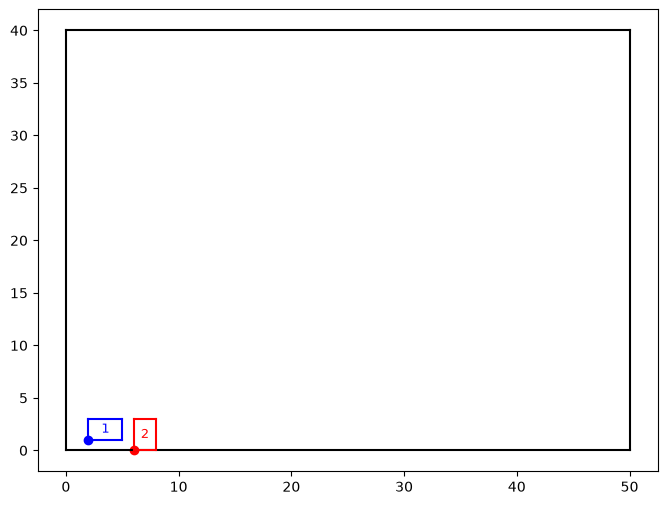

In [119]:
def plotar_caixa(bottom_left: list,
                 l: int,
                 w: int,
                 color: str,
                 label: str):
    x0, y0 = bottom_left
    plt.scatter(x=x0, y=y0, color=color)
    plt.plot([x0, x0 + l], [y0, y0], color=color)
    plt.plot([x0, x0], [y0, y0 + w], color=color)
    plt.plot([x0, x0 + l], [y0 + w, y0 + w], color=color)
    plt.plot([x0 + l, x0 + l], [y0, y0 + w], color=color)
    plt.text(x=x0 + l/2, y=y0 + w/2, s=label, color=color,
             fontsize=9, ha="center", va="center")

def plotar_palete(L: int, W: int):
    plt.figure(figsize=(8, 6))
    plt.plot([0, L], [0, 0], "k-")
    plt.plot([0, 0], [0, W], "k-")
    plt.plot([0, L], [W, W], "k-")
    plt.plot([L, L], [0, W], "k-")

plotar_palete(L, W)
plotar_caixa(bottom_left=[2, 1], l=3, w=2, color="blue", label="1")
plotar_caixa(bottom_left=[6, 0], l=2, w=3, color="red", label="2")

In [120]:
f_um = lambda n_um, l_um, n_dois, l_dois: \
    n_um * l_um + n_dois * l_dois

f_dois = lambda n_um, w_um, n_dois, w_dois:\
    n_um * w_um + n_dois * w_dois


In [121]:
print(f_um(n_um=1, l_um=3, n_dois=2, l_dois=2))     # p <= L - w_um
print(f_dois(n_um=2, w_um=2, n_dois=0, w_dois=3))   # q <= W - w_um

7
4


C:\Users\Paulo Araujo\AppData\Local\Temp\ipykernel_21964\1638786159.py:16: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(8, 6))


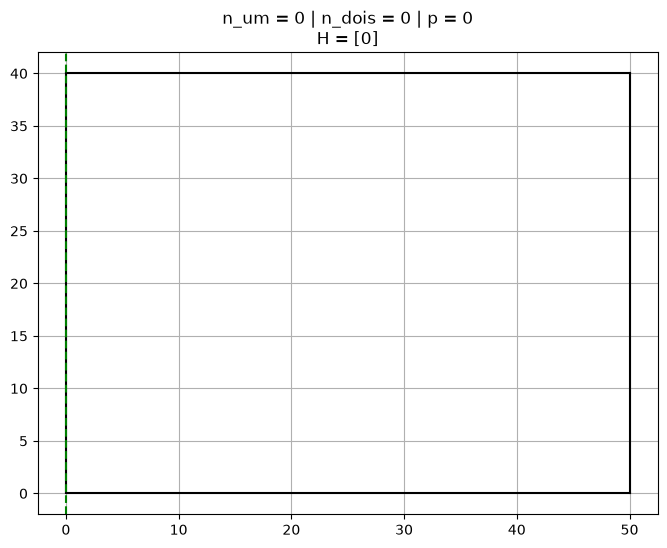

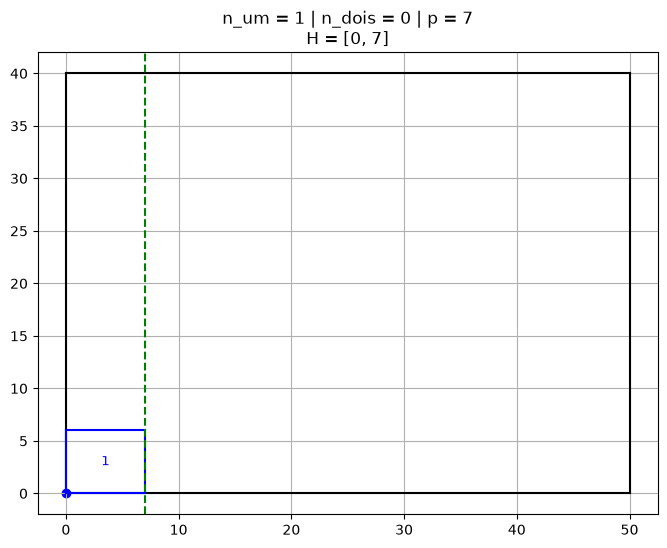

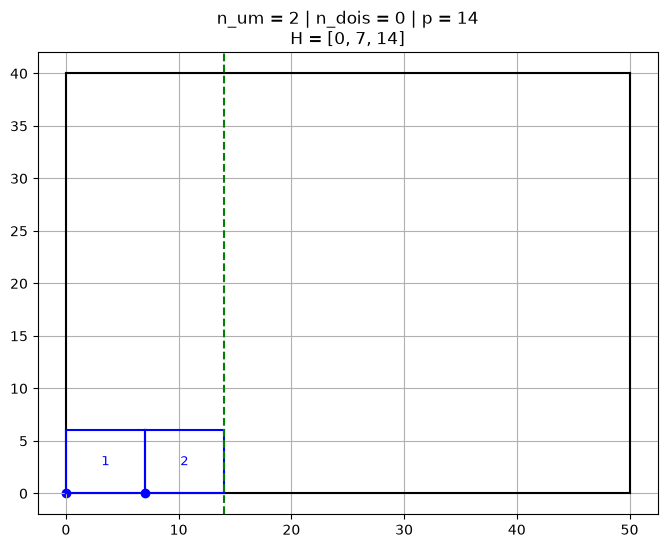

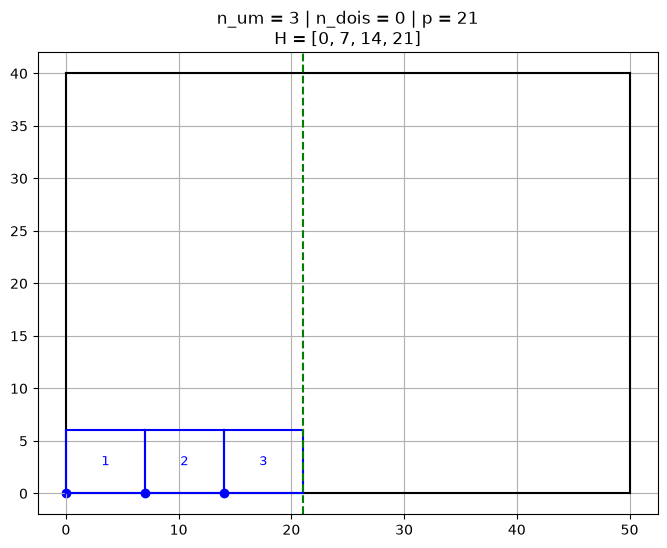

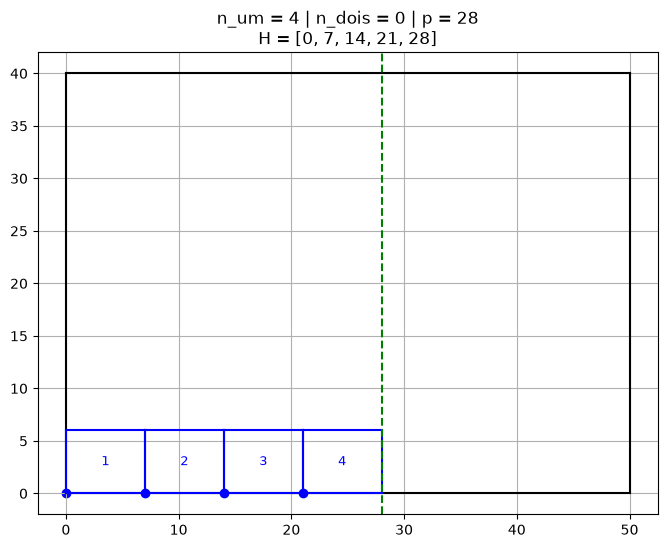

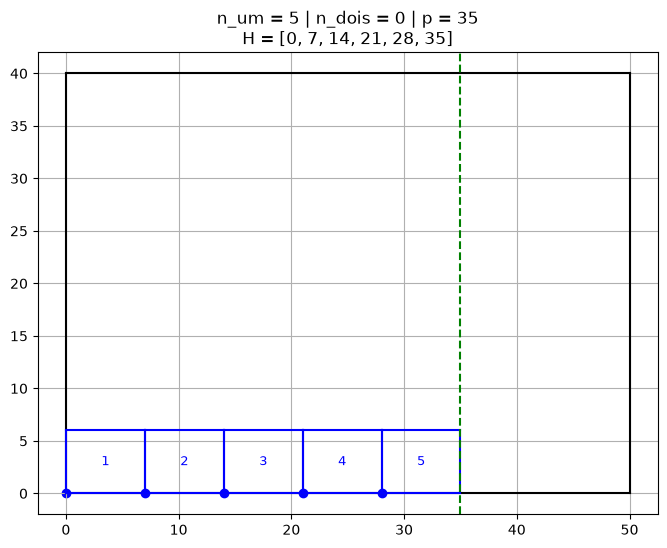

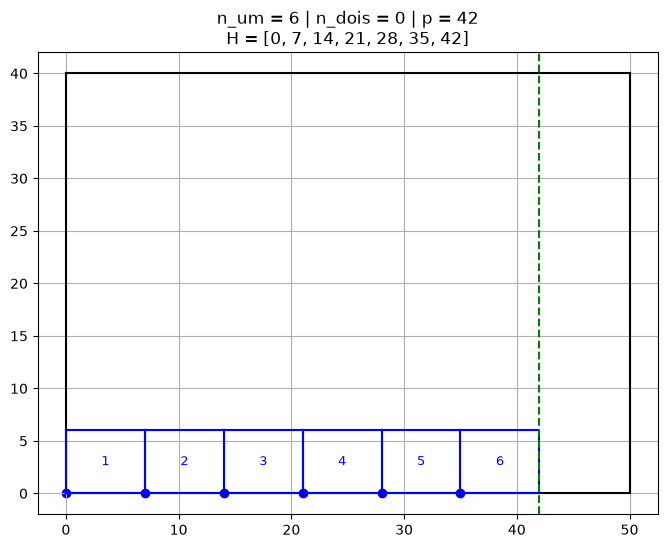

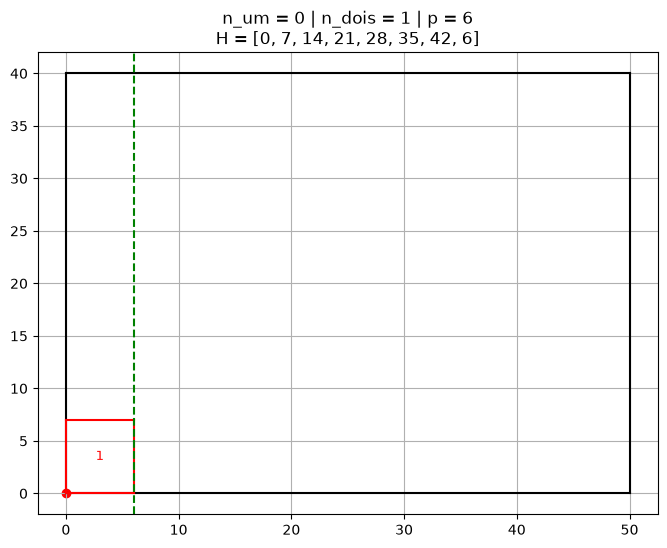

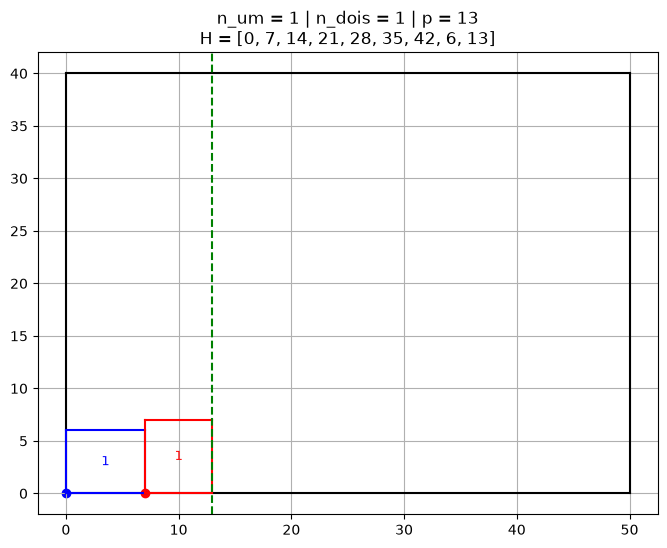

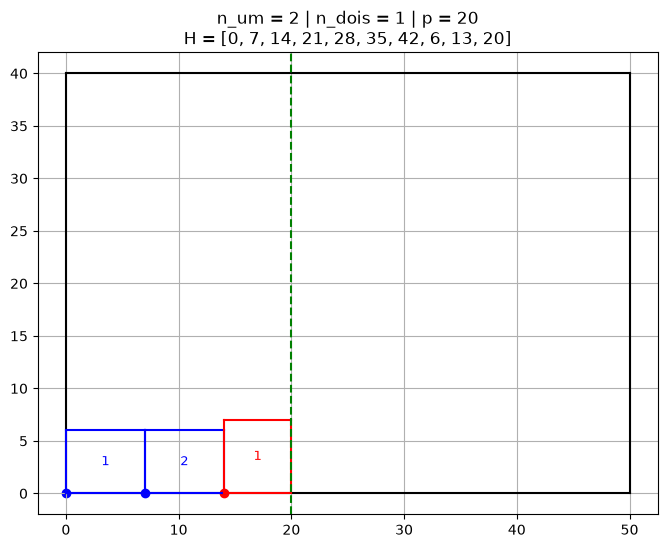

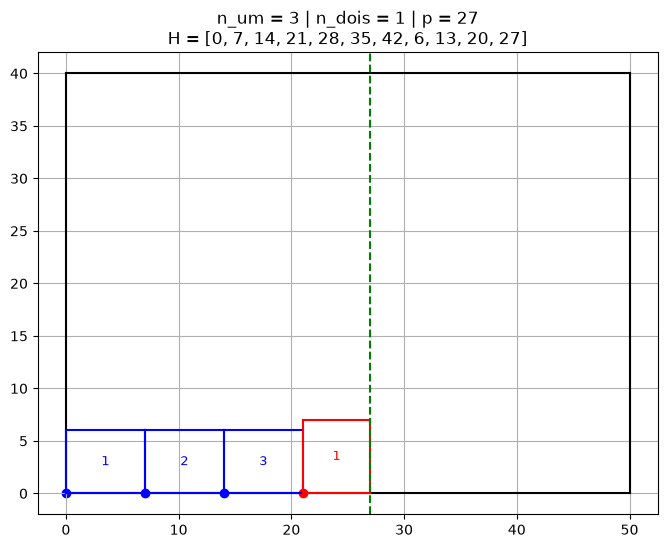

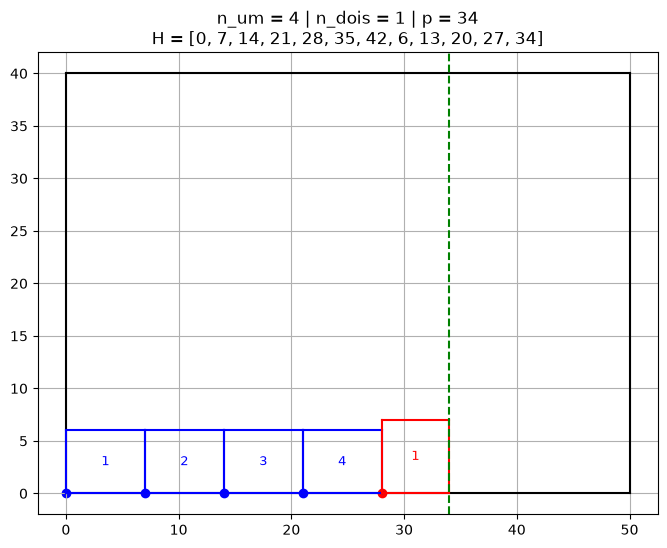

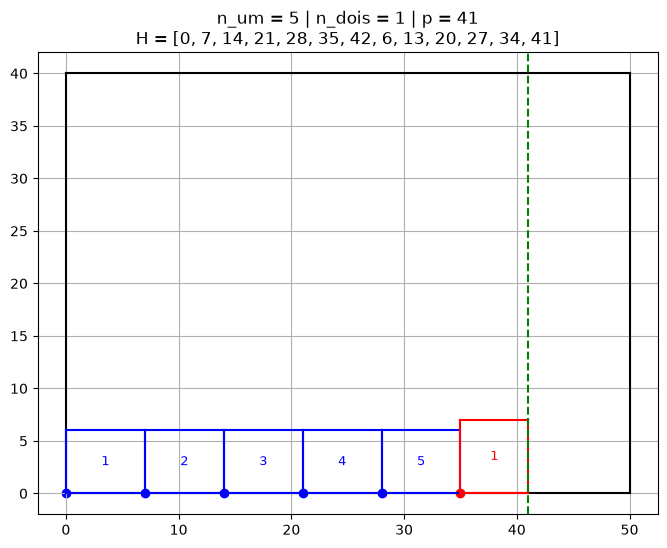

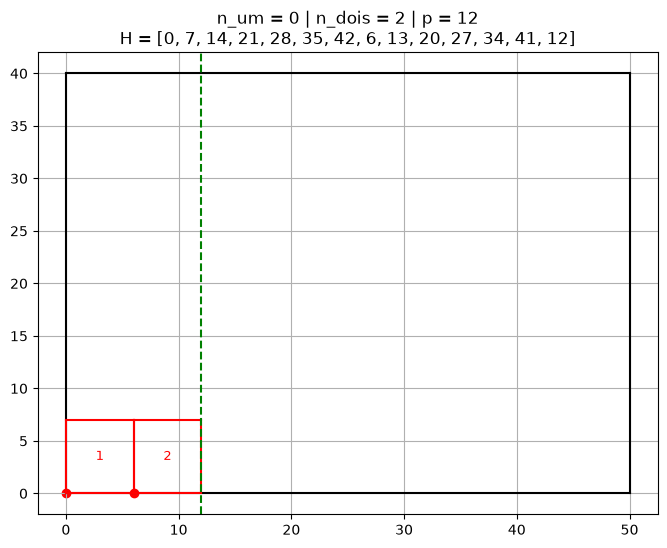

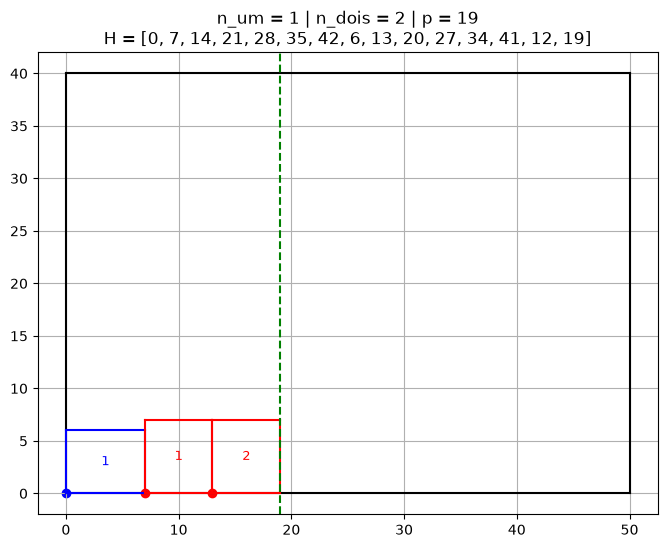

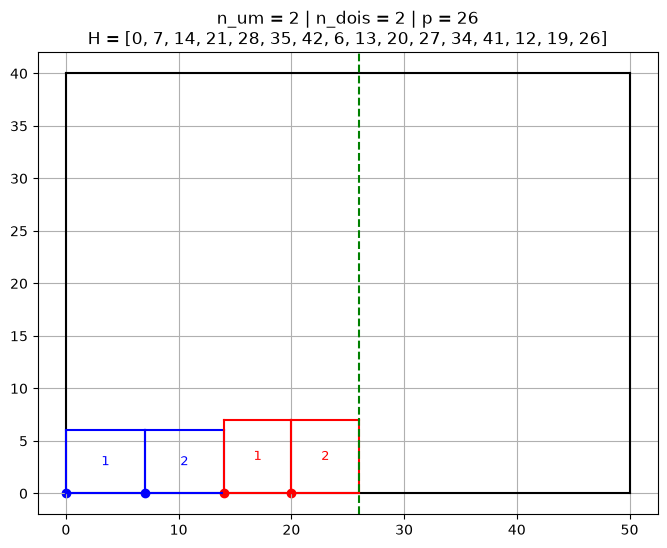

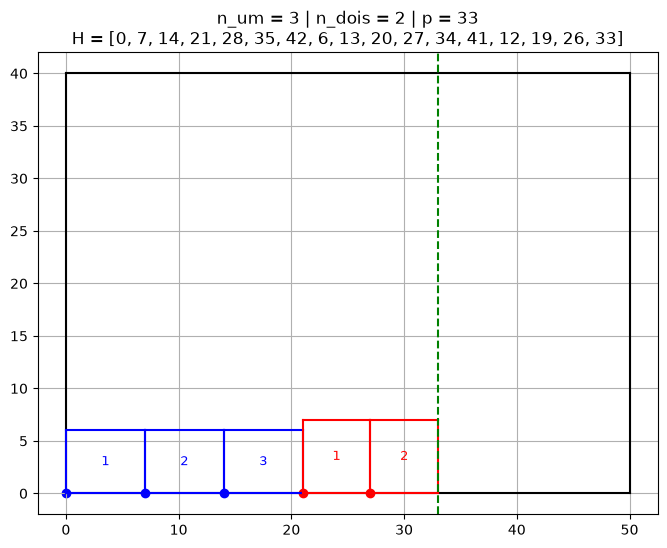

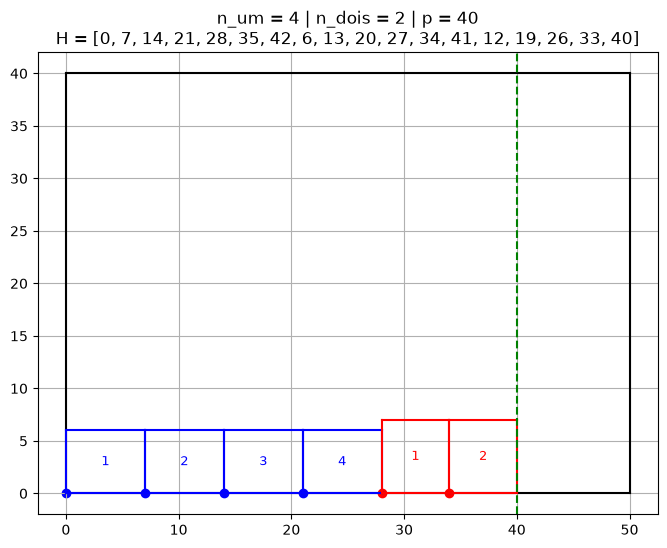

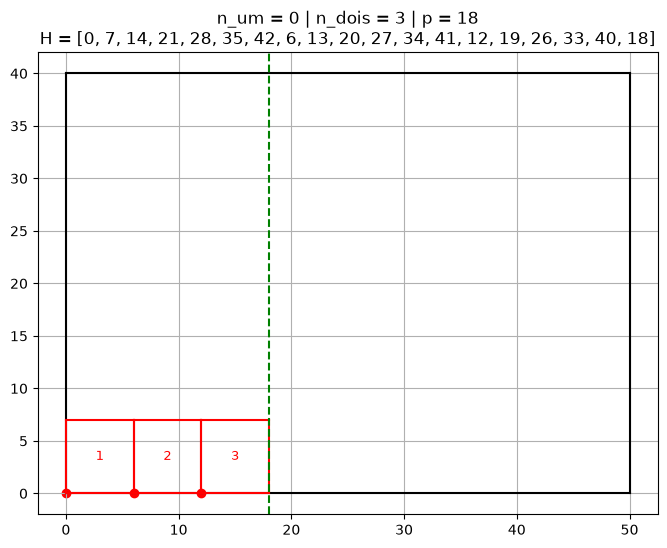

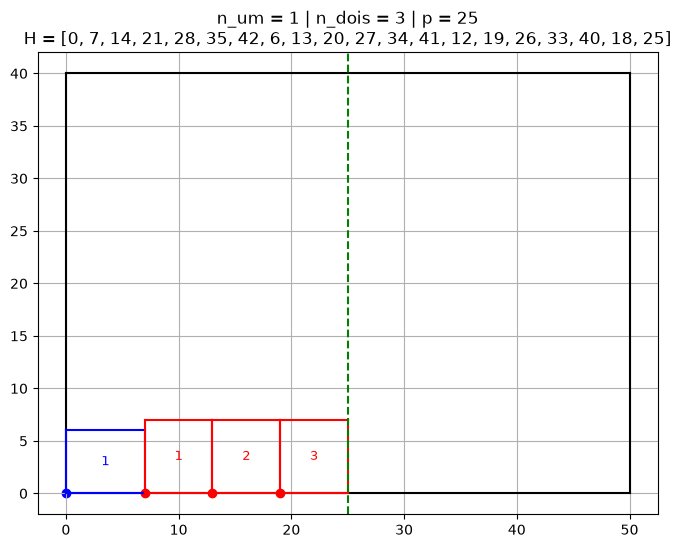

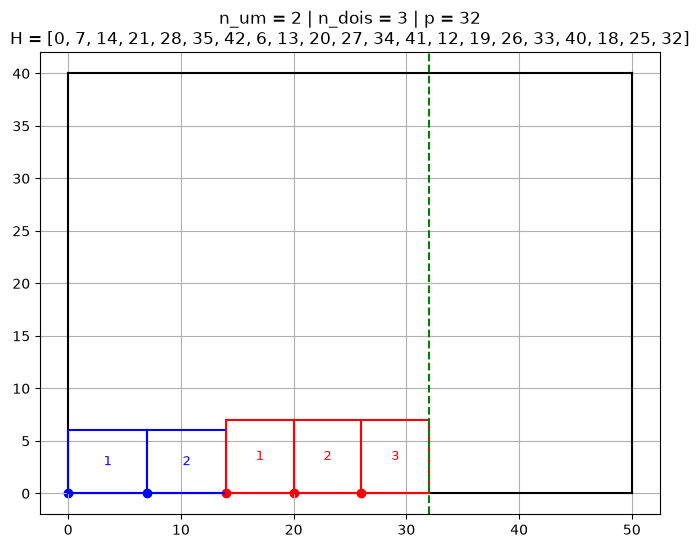

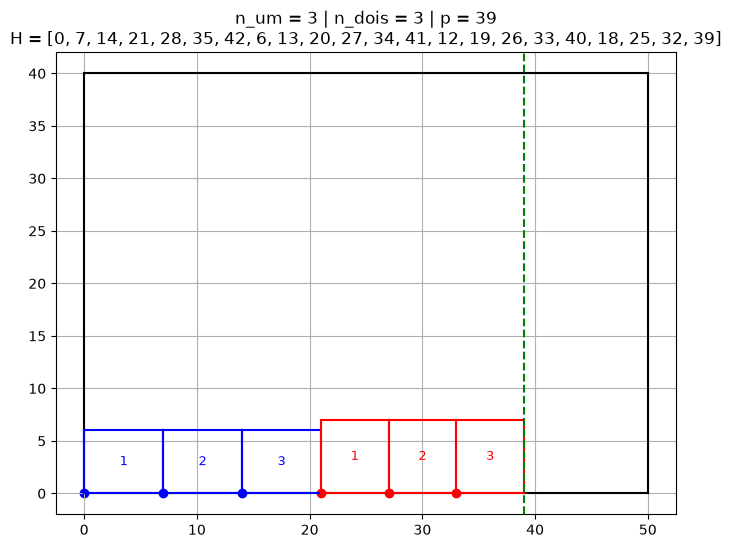

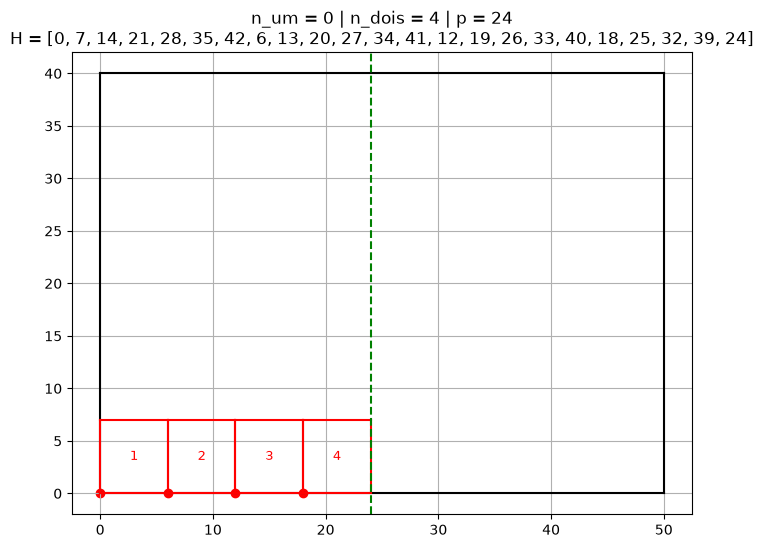

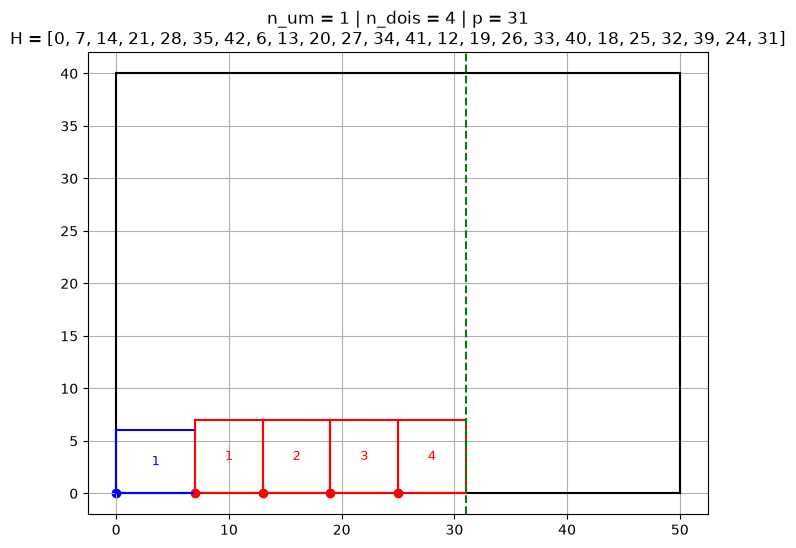

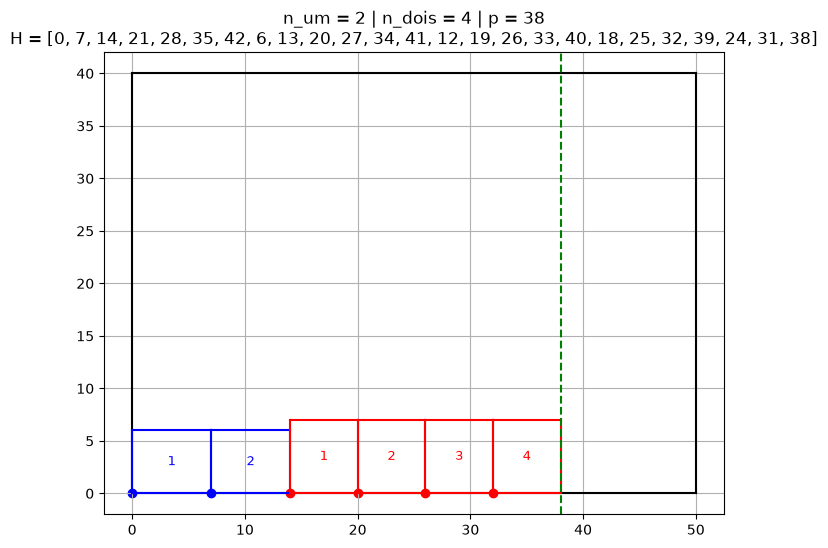

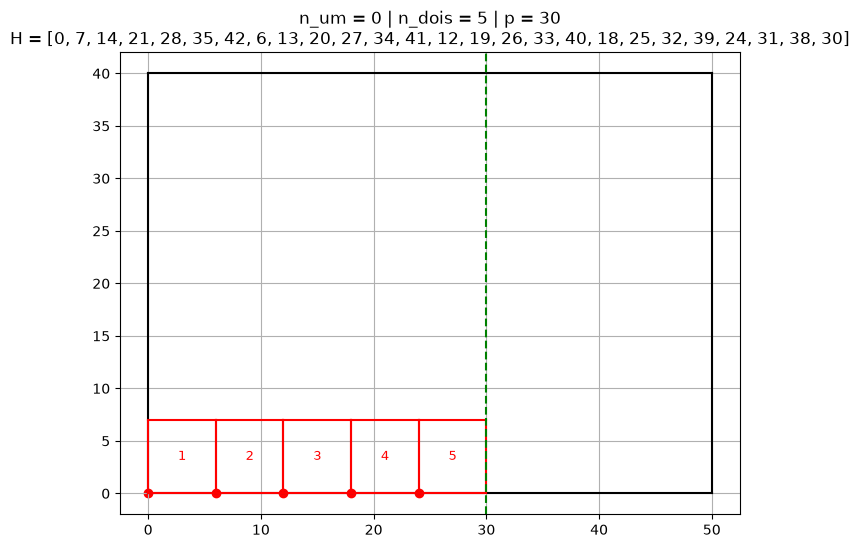

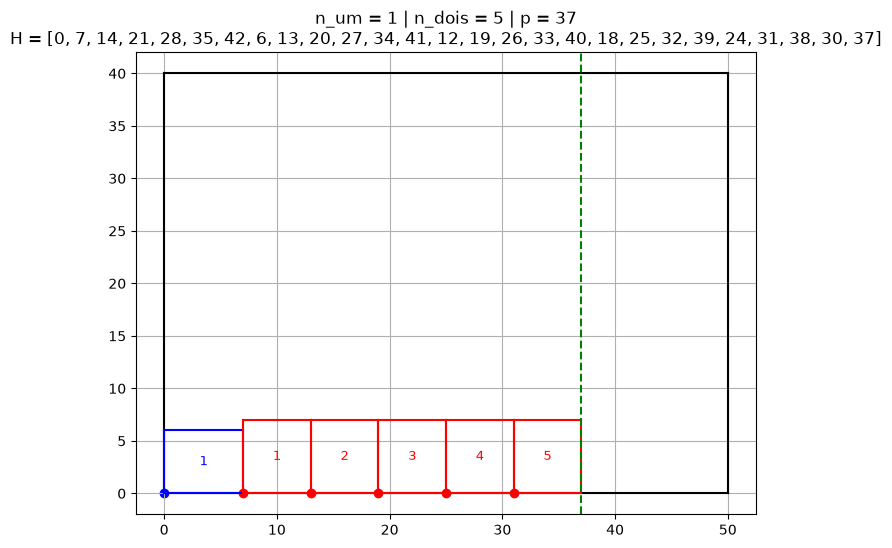

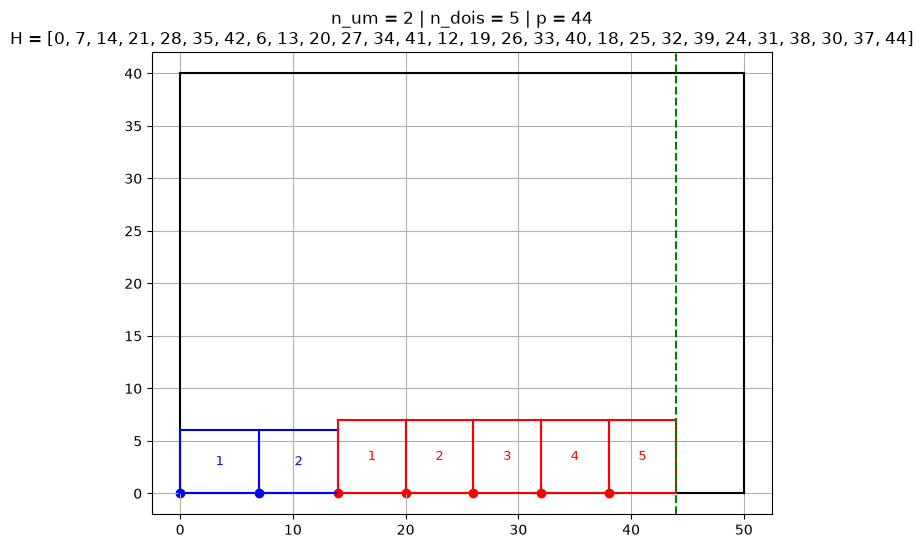

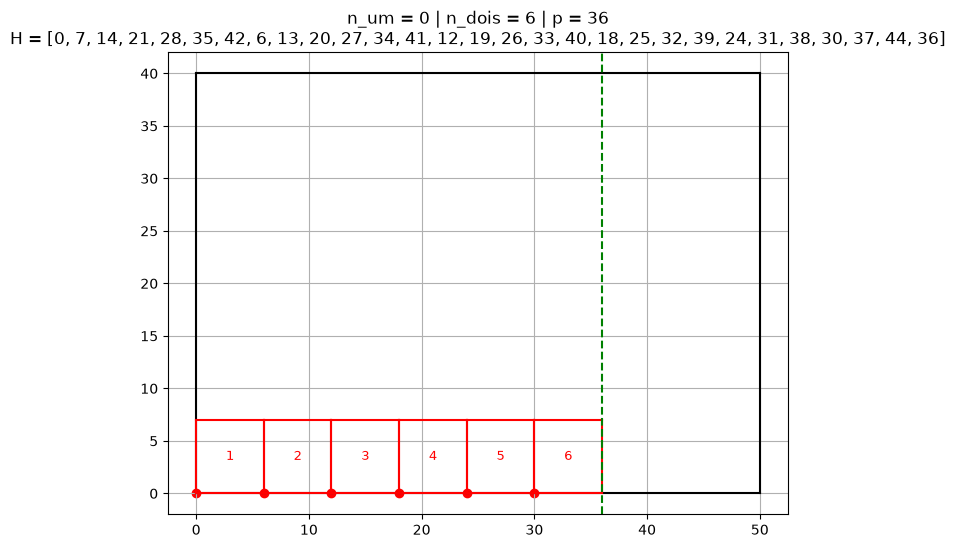

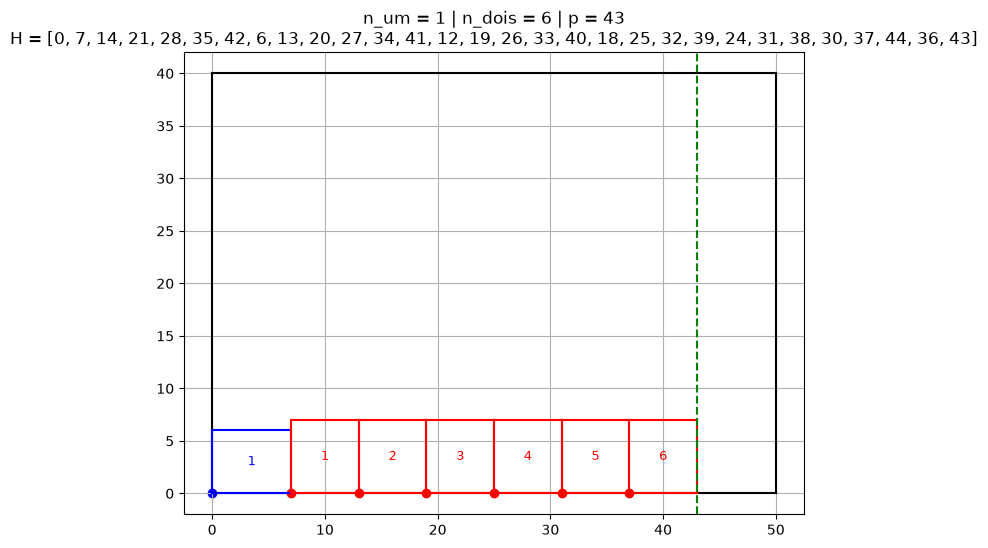

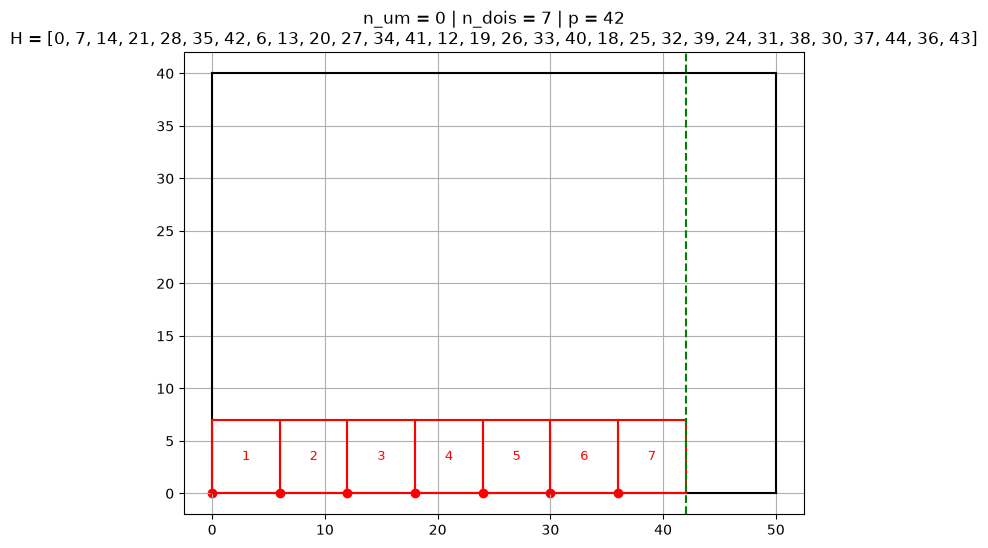

In [122]:
H = []
for n_dois, n_um in product(range(L), range(L)):
    # print(n_um, n_dois)
    p = f_um(n_um, l_um, n_dois, l_dois)
    # print(n_um, n_dois, p)
    # aqui tentar criar logica que faça ele parar e já recomecar com outra variação de nao atender a "restrição"
    if p <= L - w_um:

        if p not in H:
            H.append(p)

        plotar_palete(L, W)

        for n in range(n_um):
            plotar_caixa(bottom_left=[n * l_um, 0], l=l_um, w=w_um,
                                      color="blue", label=n+1)

        for n in range(n_dois):
            plotar_caixa(bottom_left=[n_um * l_um + n * l_dois, 0],
                        l=l_dois, w=w_dois, color="red",
                        label=n+1)
        # só vai mostrar os que deram certo

        plt.axvline(x=p, color="green", linestyle= "--")
        plt.title(f"{n_um = } | {n_dois = } | {p = }\n{H = }")
        plt.grid()
        

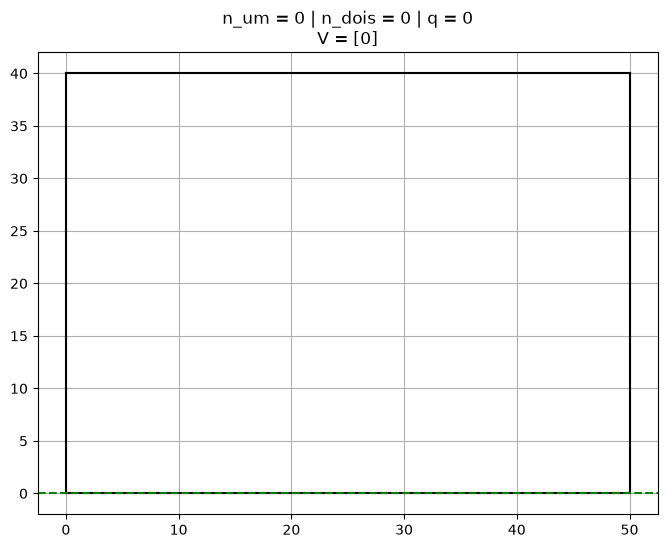

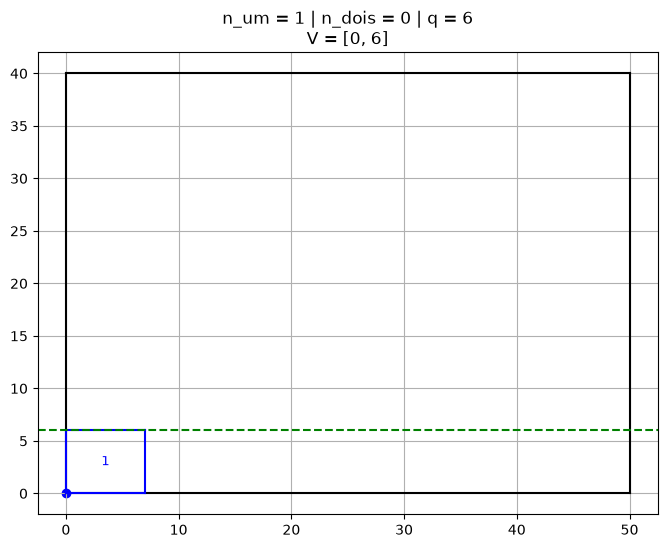

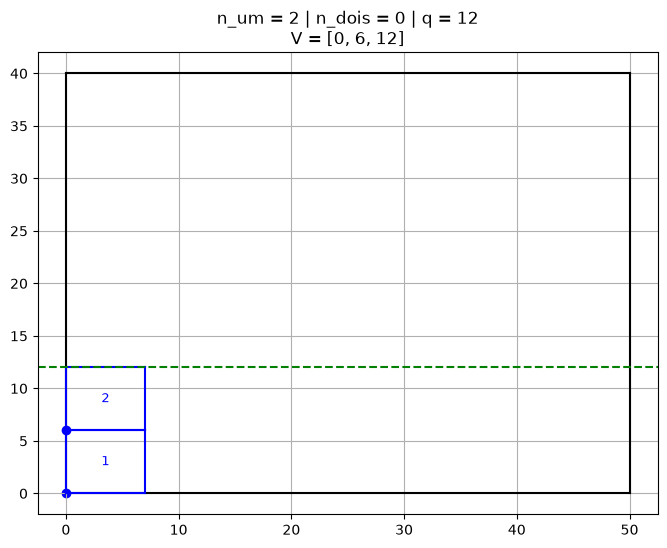

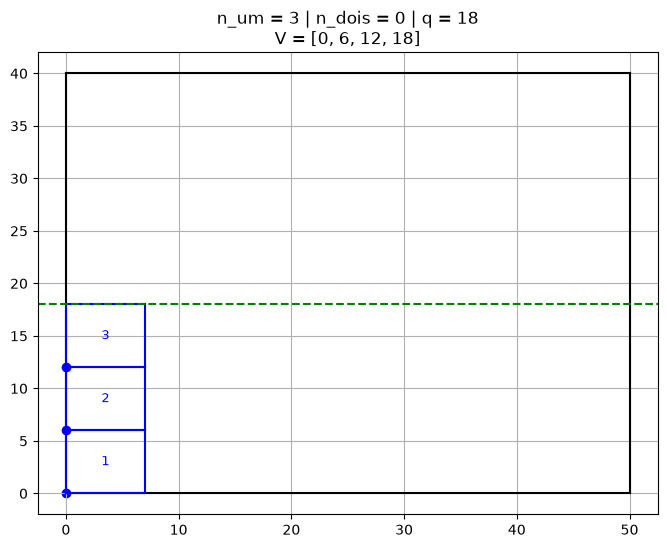

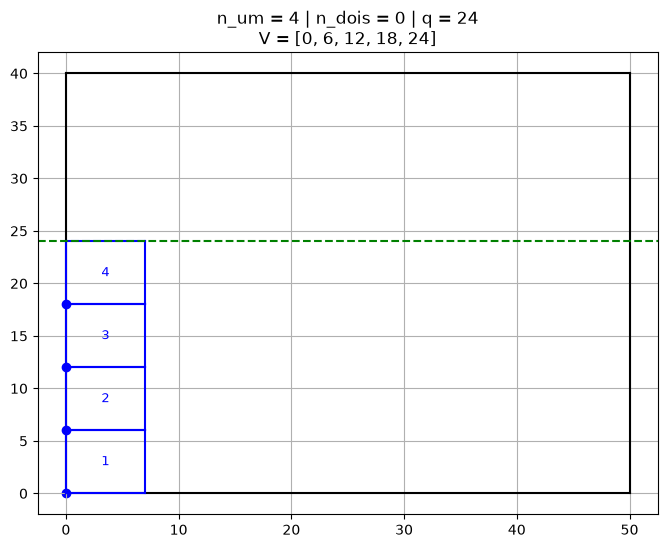

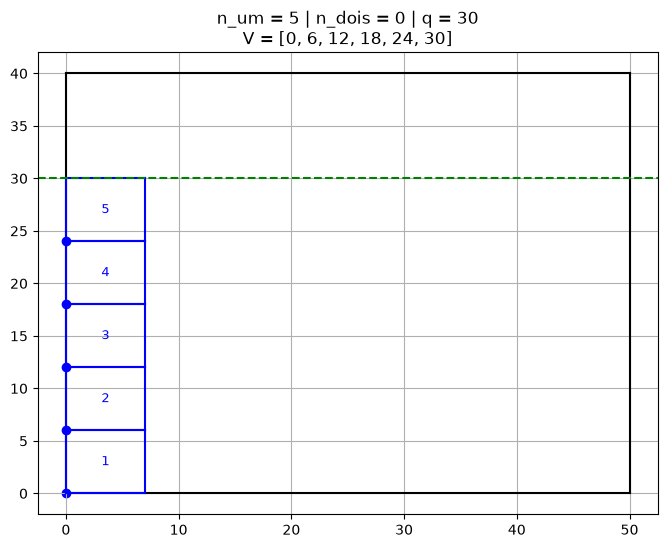

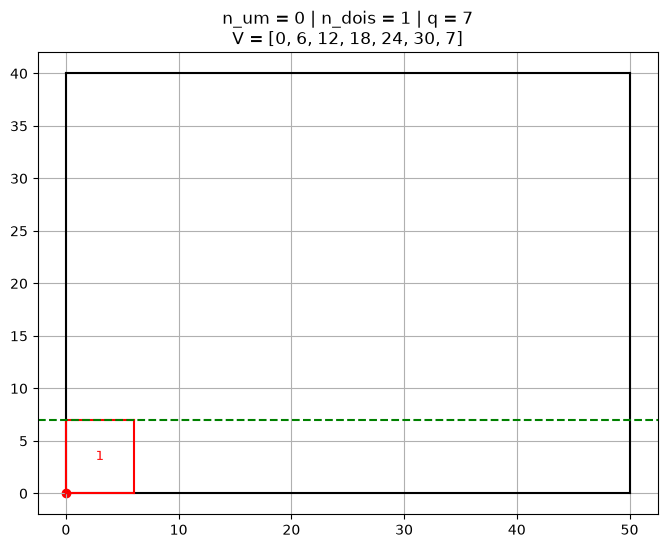

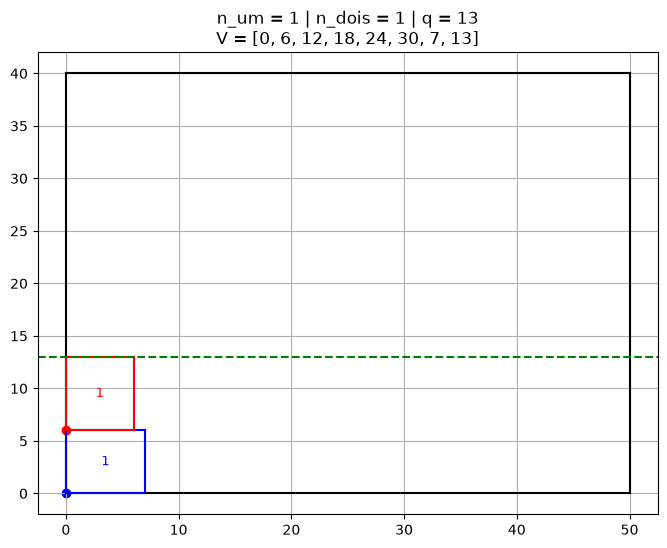

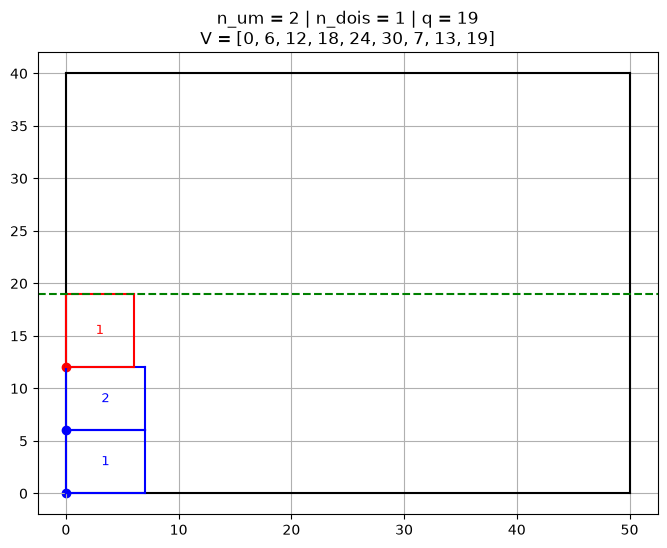

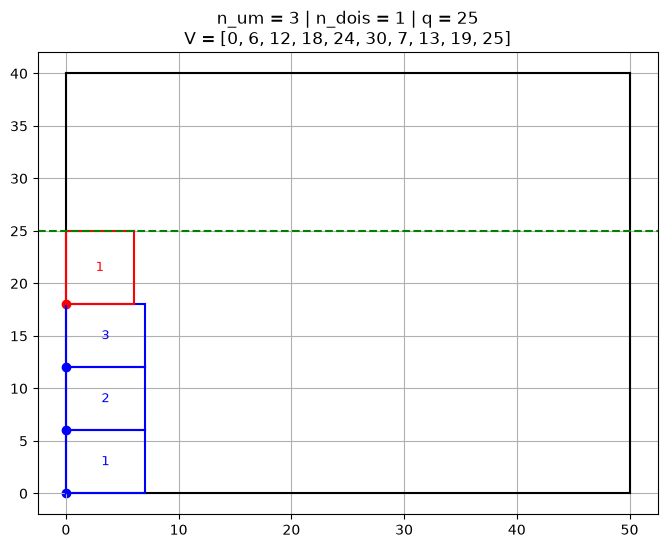

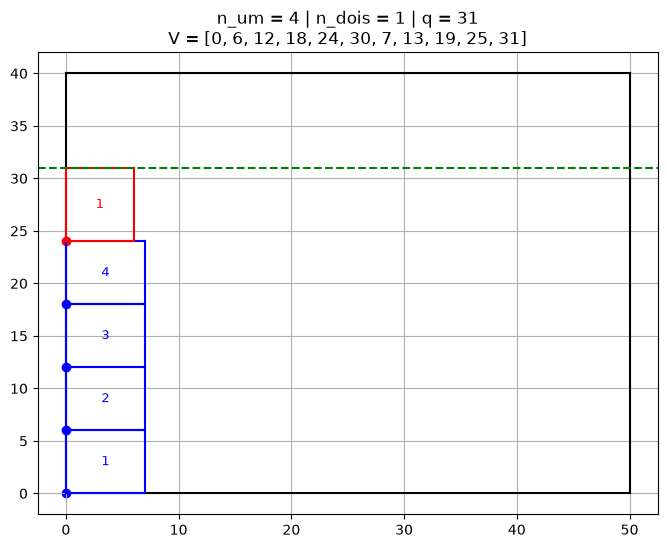

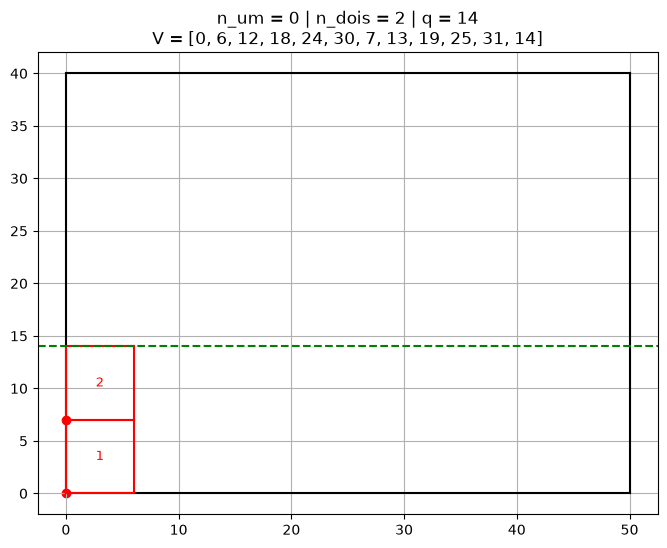

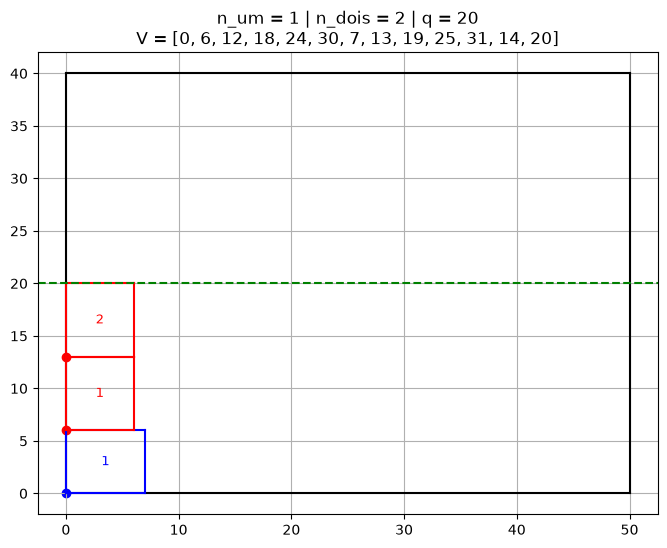

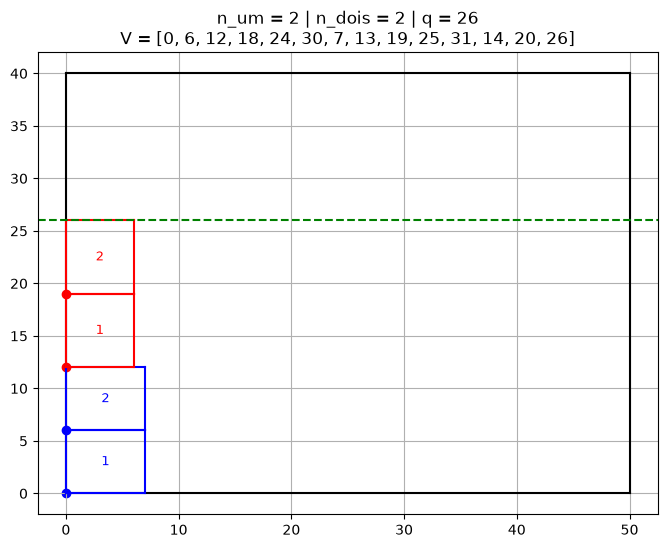

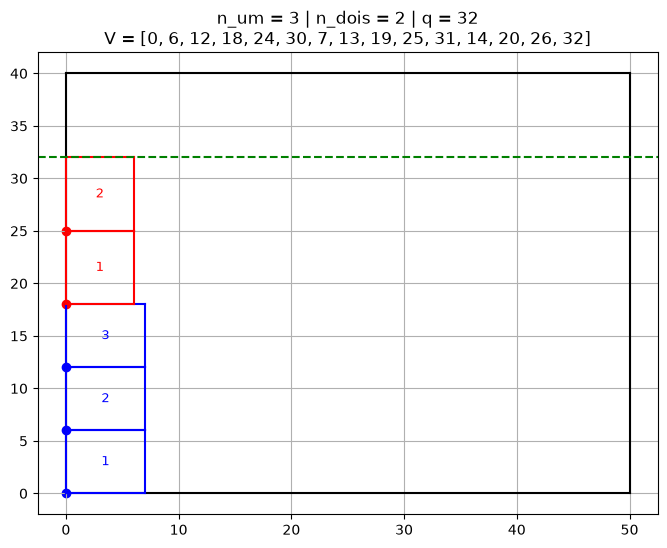

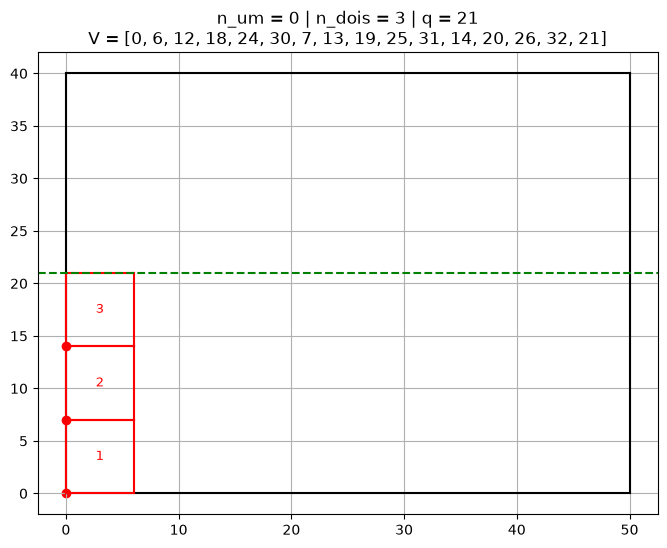

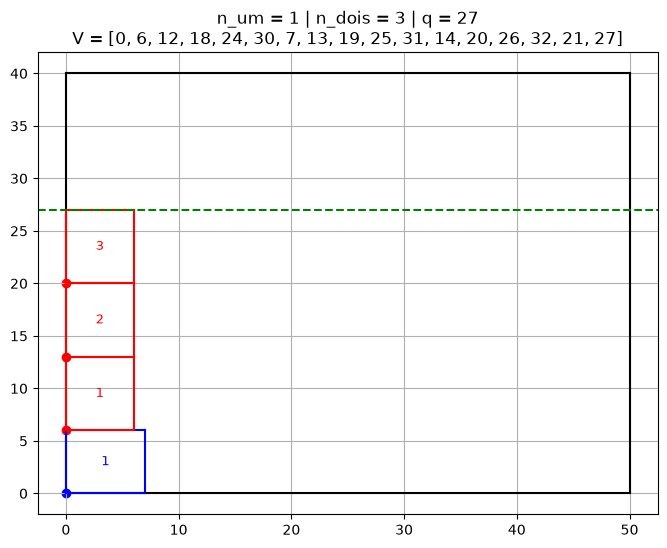

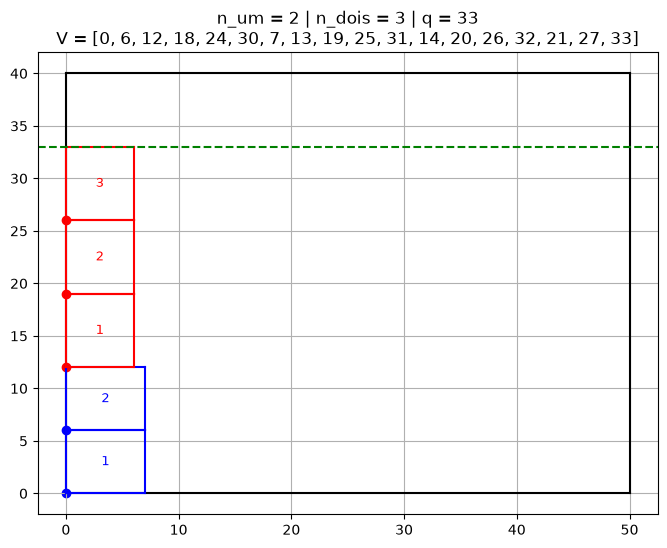

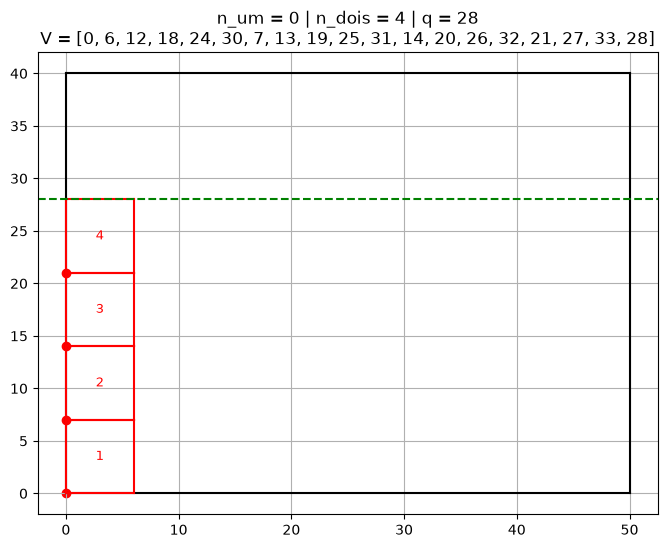

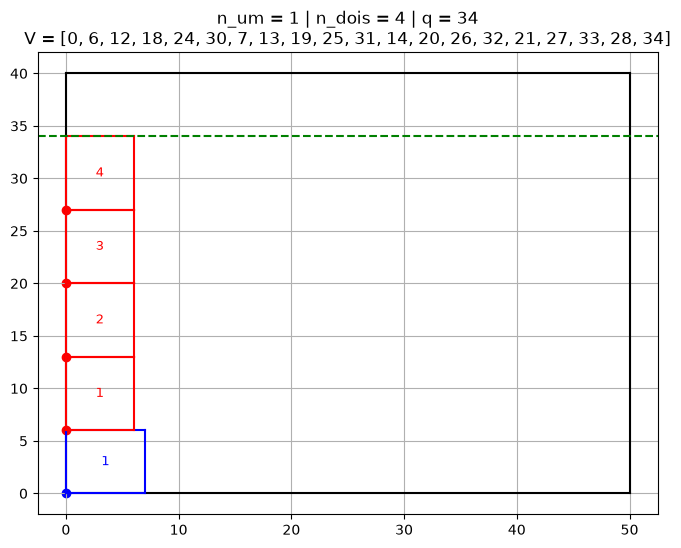

In [123]:
V = []
for n_dois, n_um in product(range(L), range(L)):
    # print(n_um, n_dois)
    q = f_dois(n_um, w_um, n_dois, w_dois)
    # print(n_um, n_dois, p)
    # aqui tentar criar logica que faça ele parar e já recomecar com outra variação de nao atender a "restrição"
    if q <= W - w_um:

        if q not in V:
            V.append(q)

        plotar_palete(L, W)

        for n in range(n_um):
            plotar_caixa(bottom_left=[0, n * w_um], l=l_um, w=w_um,
                                      color="blue", label=n+1)

        for n in range(n_dois):
            plotar_caixa(bottom_left=[0, n_um * w_um + n * w_dois],
                        l=l_dois, w=w_dois, color="red",
                        label=n+1)
        # só vai mostrar os que deram certo

        plt.axhline(y=q, color="green", linestyle= "--")
        plt.title(f"{n_um = } | {n_dois = } | {q = }\n{V = }")
        plt.grid()
        

In [124]:
H = sorted(H)
V = sorted(V)
print(H)
print(V)

[0, 6, 7, 12, 13, 14, 18, 19, 20, 21, 24, 25, 26, 27, 28, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44]
[0, 6, 7, 12, 13, 14, 18, 19, 20, 21, 24, 25, 26, 27, 28, 30, 31, 32, 33, 34]


In [125]:
lista_rs = list(product(H, V))
display(lista_rs)

[(0, 0),
 (0, 6),
 (0, 7),
 (0, 12),
 (0, 13),
 (0, 14),
 (0, 18),
 (0, 19),
 (0, 20),
 (0, 21),
 (0, 24),
 (0, 25),
 (0, 26),
 (0, 27),
 (0, 28),
 (0, 30),
 (0, 31),
 (0, 32),
 (0, 33),
 (0, 34),
 (6, 0),
 (6, 6),
 (6, 7),
 (6, 12),
 (6, 13),
 (6, 14),
 (6, 18),
 (6, 19),
 (6, 20),
 (6, 21),
 (6, 24),
 (6, 25),
 (6, 26),
 (6, 27),
 (6, 28),
 (6, 30),
 (6, 31),
 (6, 32),
 (6, 33),
 (6, 34),
 (7, 0),
 (7, 6),
 (7, 7),
 (7, 12),
 (7, 13),
 (7, 14),
 (7, 18),
 (7, 19),
 (7, 20),
 (7, 21),
 (7, 24),
 (7, 25),
 (7, 26),
 (7, 27),
 (7, 28),
 (7, 30),
 (7, 31),
 (7, 32),
 (7, 33),
 (7, 34),
 (12, 0),
 (12, 6),
 (12, 7),
 (12, 12),
 (12, 13),
 (12, 14),
 (12, 18),
 (12, 19),
 (12, 20),
 (12, 21),
 (12, 24),
 (12, 25),
 (12, 26),
 (12, 27),
 (12, 28),
 (12, 30),
 (12, 31),
 (12, 32),
 (12, 33),
 (12, 34),
 (13, 0),
 (13, 6),
 (13, 7),
 (13, 12),
 (13, 13),
 (13, 14),
 (13, 18),
 (13, 19),
 (13, 20),
 (13, 21),
 (13, 24),
 (13, 25),
 (13, 26),
 (13, 27),
 (13, 28),
 (13, 30),
 (13, 31),
 (13, 32

In [126]:
if indice == 0:
    plotar_palete(L, W)
    for r, s in lista_rs:
        plt.scatter(x=r, y=s, color="purple")

    plt.title("Possibilidades de bottom-left para as caixas")
    plt.grid()
    plt.show()

In [127]:
ls = [l_um, l_dois]
ws = [w_um, w_dois]

In [128]:
i = 1 # se por i =2 ele inverte
print(ls[i-1], ws[i-1])


7 6


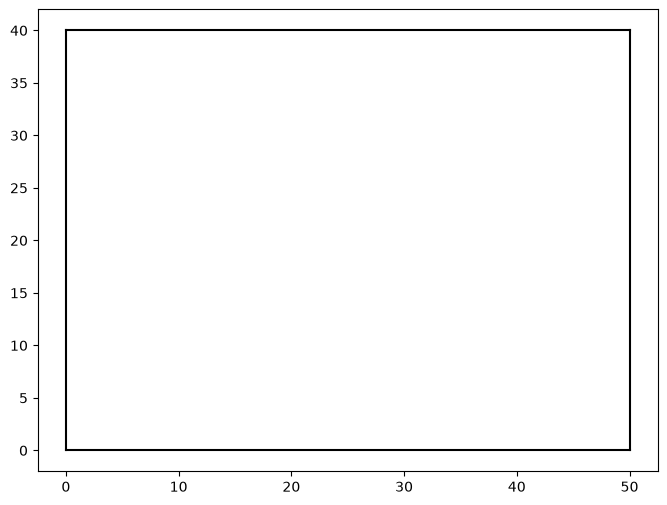

In [129]:
lista_variaveis = []
plotar_palete(L, W)
# for i, (p, q) in product([1, 2], lista_rs):# só para inverter a ordem para voce testar
for (p, q), i in product(lista_rs, [1, 2]): 
    # print(i, p, q)
    # i = 1 caixa deitada
    # i = 2 caixa em pé
    if p + ls[i-1] <= L and q + ws[i-1] <= W: # checa se cabe no palete
        lista_variaveis.append((i, p, q))

        if indice == 0:
            cor = "blue" if i == 1 else "red"
            plt.scatter(x=p, y=q, color=cor)    # plota o bottom left

            if i == 1:
                plt.text(x=p - 0.3, y=q + 0.15, s=f"({i}, {p}, {q})",
                color=cor, fontsize=10)

            else:
                plt.text(x=p - 0.3, y=q - 0.25, s=f"({i}, {p}, {q})",
                        color=cor, fontsize=10)

In [130]:
print(len(lista_variaveis))

1150


In [131]:
prob = plp.LpProblem(name="Palete-Caixa",
                     sense=plp.LpMaximize)
display(prob)

Palete-Caixa:
MAXIMIZE
None
VARIABLES

In [132]:
dict_variaveis = plp.LpVariable.dicts(name="C", indices=lista_variaveis,
                                      lowBound=0, upBound=1,
                                      cat=plp.LpBinary)
display(dict_variaveis)

{(1, 0, 0): C_(1,_0,_0),
 (2, 0, 0): C_(2,_0,_0),
 (1, 0, 6): C_(1,_0,_6),
 (2, 0, 6): C_(2,_0,_6),
 (1, 0, 7): C_(1,_0,_7),
 (2, 0, 7): C_(2,_0,_7),
 (1, 0, 12): C_(1,_0,_12),
 (2, 0, 12): C_(2,_0,_12),
 (1, 0, 13): C_(1,_0,_13),
 (2, 0, 13): C_(2,_0,_13),
 (1, 0, 14): C_(1,_0,_14),
 (2, 0, 14): C_(2,_0,_14),
 (1, 0, 18): C_(1,_0,_18),
 (2, 0, 18): C_(2,_0,_18),
 (1, 0, 19): C_(1,_0,_19),
 (2, 0, 19): C_(2,_0,_19),
 (1, 0, 20): C_(1,_0,_20),
 (2, 0, 20): C_(2,_0,_20),
 (1, 0, 21): C_(1,_0,_21),
 (2, 0, 21): C_(2,_0,_21),
 (1, 0, 24): C_(1,_0,_24),
 (2, 0, 24): C_(2,_0,_24),
 (1, 0, 25): C_(1,_0,_25),
 (2, 0, 25): C_(2,_0,_25),
 (1, 0, 26): C_(1,_0,_26),
 (2, 0, 26): C_(2,_0,_26),
 (1, 0, 27): C_(1,_0,_27),
 (2, 0, 27): C_(2,_0,_27),
 (1, 0, 28): C_(1,_0,_28),
 (2, 0, 28): C_(2,_0,_28),
 (1, 0, 30): C_(1,_0,_30),
 (2, 0, 30): C_(2,_0,_30),
 (1, 0, 31): C_(1,_0,_31),
 (2, 0, 31): C_(2,_0,_31),
 (1, 0, 32): C_(1,_0,_32),
 (2, 0, 32): C_(2,_0,_32),
 (1, 0, 33): C_(1,_0,_33),
 (2, 0, 33): 

---
### Inicioa aula 2 Paleta de caixa

In [133]:
# dict_variaveis.values()
prob += sum(dict_variaveis.values())
display(prob)

Palete-Caixa:
MAXIMIZE
1*C_(1,_0,_0) + 1*C_(1,_0,_12) + 1*C_(1,_0,_13) + 1*C_(1,_0,_14) + 1*C_(1,_0,_18) + 1*C_(1,_0,_19) + 1*C_(1,_0,_20) + 1*C_(1,_0,_21) + 1*C_(1,_0,_24) + 1*C_(1,_0,_25) + 1*C_(1,_0,_26) + 1*C_(1,_0,_27) + 1*C_(1,_0,_28) + 1*C_(1,_0,_30) + 1*C_(1,_0,_31) + 1*C_(1,_0,_32) + 1*C_(1,_0,_33) + 1*C_(1,_0,_34) + 1*C_(1,_0,_6) + 1*C_(1,_0,_7) + 1*C_(1,_12,_0) + 1*C_(1,_12,_12) + 1*C_(1,_12,_13) + 1*C_(1,_12,_14) + 1*C_(1,_12,_18) + 1*C_(1,_12,_19) + 1*C_(1,_12,_20) + 1*C_(1,_12,_21) + 1*C_(1,_12,_24) + 1*C_(1,_12,_25) + 1*C_(1,_12,_26) + 1*C_(1,_12,_27) + 1*C_(1,_12,_28) + 1*C_(1,_12,_30) + 1*C_(1,_12,_31) + 1*C_(1,_12,_32) + 1*C_(1,_12,_33) + 1*C_(1,_12,_34) + 1*C_(1,_12,_6) + 1*C_(1,_12,_7) + 1*C_(1,_13,_0) + 1*C_(1,_13,_12) + 1*C_(1,_13,_13) + 1*C_(1,_13,_14) + 1*C_(1,_13,_18) + 1*C_(1,_13,_19) + 1*C_(1,_13,_20) + 1*C_(1,_13,_21) + 1*C_(1,_13,_24) + 1*C_(1,_13,_25) + 1*C_(1,_13,_26) + 1*C_(1,_13,_27) + 1*C_(1,_13,_28) + 1*C_(1,_13,_30) + 1*C_(1,_13,_31) + 1*C_(1,_13,_32

In [134]:
print(f"Qtd variáveis: {prob.numVariables()}")
print(f"Qtd restrições: {prob.numConstraints()}")

Qtd variáveis: 1150
Qtd restrições: 0


In [135]:
# def ponto_dentro_caixa(ponto_rs: tuple,
#                        ponto_pq: tuple,
#                        l: int, w: int) -> bool:
#     r, s = ponto_rs
#     p, q = ponto_pq
#     return p <= r <= p + l and q <= s <= q + w
# print(ponto_dentro_caixa((6, 4),
#                          (5, 2),
#                          l=ls[0], w=ws[0]))

In [136]:
# def ponto_dentro_caixa(ponto_rs: tuple,
#                        ponto_pq: tuple,
#                        l: int, w: int) -> bool:
#     r, s = ponto_rs
#     p, q = ponto_pq
#     return p <= r < p + l and q <= s < q + w
# print(ponto_dentro_caixa((6, 2),
#                          (6, 0),
#                          l=ls[1], w=ws[1]))

In [137]:
def ponto_dentro_caixa(ponto_rs: tuple,
                       ponto_pq: tuple,
                       l: int, w: int) -> bool:
    r, s = ponto_rs
    p, q = ponto_pq
    return p <= r < p + l and q <= s < q + w
print(ponto_dentro_caixa((6, 2),
                         (6, 0),
                         l=ls[0], w=ws[0]))

True


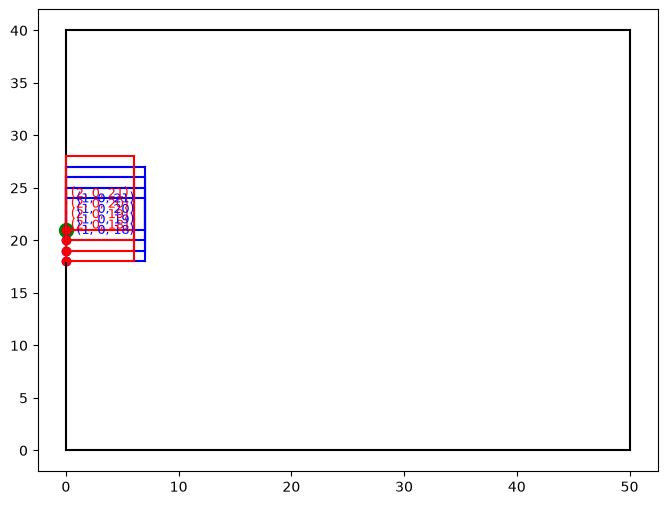

In [138]:
plotar_palete(L, W)
r, s = lista_rs[9]
plt.scatter(x=r, y=s, color="green", s=100)
caixas_sobrepostas = []
for i, p, q in lista_variaveis:
    if ponto_dentro_caixa((r, s),
                          (p, q),
                          l=ls[i-1], w=ws[i-1]):
        plotar_caixa((p, q), ls[i-1], ws[i-1],
                     color="blue" if i == 1 else "red",
                     label=f"{i, p, q}")

In [139]:
sorted([(2, 0, 1), (1, 1, 2)]) #teste para visulizar melhor a celula debaixo pra seguir o ppt(pdf)

[(1, 1, 2), (2, 0, 1)]

In [140]:
# r, s = lista_rs[9]
n=0
for r, s in lista_rs:
    caixas_sobrepostas = []
    for i, p, q in lista_variaveis:
        if ponto_dentro_caixa((r, s),
                            (p, q),
                            l=ls[i-1], w=ws[i-1]):
            caixas_sobrepostas.append(dict_variaveis[(i, p, q)])
    # print(sorted(caixas_sobrepostas))
    # print(sum(caixas_sobrepostas))
    prob += sum(caixas_sobrepostas) <= 1, f"Restricao 1.{n}"
    n += 1

In [141]:
display(prob)

Palete-Caixa:
MAXIMIZE
1*C_(1,_0,_0) + 1*C_(1,_0,_12) + 1*C_(1,_0,_13) + 1*C_(1,_0,_14) + 1*C_(1,_0,_18) + 1*C_(1,_0,_19) + 1*C_(1,_0,_20) + 1*C_(1,_0,_21) + 1*C_(1,_0,_24) + 1*C_(1,_0,_25) + 1*C_(1,_0,_26) + 1*C_(1,_0,_27) + 1*C_(1,_0,_28) + 1*C_(1,_0,_30) + 1*C_(1,_0,_31) + 1*C_(1,_0,_32) + 1*C_(1,_0,_33) + 1*C_(1,_0,_34) + 1*C_(1,_0,_6) + 1*C_(1,_0,_7) + 1*C_(1,_12,_0) + 1*C_(1,_12,_12) + 1*C_(1,_12,_13) + 1*C_(1,_12,_14) + 1*C_(1,_12,_18) + 1*C_(1,_12,_19) + 1*C_(1,_12,_20) + 1*C_(1,_12,_21) + 1*C_(1,_12,_24) + 1*C_(1,_12,_25) + 1*C_(1,_12,_26) + 1*C_(1,_12,_27) + 1*C_(1,_12,_28) + 1*C_(1,_12,_30) + 1*C_(1,_12,_31) + 1*C_(1,_12,_32) + 1*C_(1,_12,_33) + 1*C_(1,_12,_34) + 1*C_(1,_12,_6) + 1*C_(1,_12,_7) + 1*C_(1,_13,_0) + 1*C_(1,_13,_12) + 1*C_(1,_13,_13) + 1*C_(1,_13,_14) + 1*C_(1,_13,_18) + 1*C_(1,_13,_19) + 1*C_(1,_13,_20) + 1*C_(1,_13,_21) + 1*C_(1,_13,_24) + 1*C_(1,_13,_25) + 1*C_(1,_13,_26) + 1*C_(1,_13,_27) + 1*C_(1,_13,_28) + 1*C_(1,_13,_30) + 1*C_(1,_13,_31) + 1*C_(1,_13,_32

In [142]:
print(prob.numVariables())
print(prob.numConstraints())

1150
600


In [143]:
qtd_maxima_caixas = ( L * W) // (l_um * w_um)
display(qtd_maxima_caixas)

47

In [144]:
prob += sum(dict_variaveis.values()) <= qtd_maxima_caixas, "Resticao_2.0"
display(prob)

Palete-Caixa:
MAXIMIZE
1*C_(1,_0,_0) + 1*C_(1,_0,_12) + 1*C_(1,_0,_13) + 1*C_(1,_0,_14) + 1*C_(1,_0,_18) + 1*C_(1,_0,_19) + 1*C_(1,_0,_20) + 1*C_(1,_0,_21) + 1*C_(1,_0,_24) + 1*C_(1,_0,_25) + 1*C_(1,_0,_26) + 1*C_(1,_0,_27) + 1*C_(1,_0,_28) + 1*C_(1,_0,_30) + 1*C_(1,_0,_31) + 1*C_(1,_0,_32) + 1*C_(1,_0,_33) + 1*C_(1,_0,_34) + 1*C_(1,_0,_6) + 1*C_(1,_0,_7) + 1*C_(1,_12,_0) + 1*C_(1,_12,_12) + 1*C_(1,_12,_13) + 1*C_(1,_12,_14) + 1*C_(1,_12,_18) + 1*C_(1,_12,_19) + 1*C_(1,_12,_20) + 1*C_(1,_12,_21) + 1*C_(1,_12,_24) + 1*C_(1,_12,_25) + 1*C_(1,_12,_26) + 1*C_(1,_12,_27) + 1*C_(1,_12,_28) + 1*C_(1,_12,_30) + 1*C_(1,_12,_31) + 1*C_(1,_12,_32) + 1*C_(1,_12,_33) + 1*C_(1,_12,_34) + 1*C_(1,_12,_6) + 1*C_(1,_12,_7) + 1*C_(1,_13,_0) + 1*C_(1,_13,_12) + 1*C_(1,_13,_13) + 1*C_(1,_13,_14) + 1*C_(1,_13,_18) + 1*C_(1,_13,_19) + 1*C_(1,_13,_20) + 1*C_(1,_13,_21) + 1*C_(1,_13,_24) + 1*C_(1,_13,_25) + 1*C_(1,_13,_26) + 1*C_(1,_13,_27) + 1*C_(1,_13,_28) + 1*C_(1,_13,_30) + 1*C_(1,_13,_31) + 1*C_(1,_13,_32

In [145]:
print(prob.numVariables())
print(prob.numConstraints())

1150
601


In [146]:
solver = plp.getSolver("PULP_CBC_CMD", timeLimit=None)

In [147]:
prob.solve(solver)

1

In [148]:
display(plp.LpStatus)

{0: 'Not Solved',
 1: 'Optimal',
 -1: 'Infeasible',
 -2: 'Unbounded',
 -3: 'Undefined'}

In [149]:
print(prob.variables())

[C_(1,_0,_0), C_(1,_0,_12), C_(1,_0,_13), C_(1,_0,_14), C_(1,_0,_18), C_(1,_0,_19), C_(1,_0,_20), C_(1,_0,_21), C_(1,_0,_24), C_(1,_0,_25), C_(1,_0,_26), C_(1,_0,_27), C_(1,_0,_28), C_(1,_0,_30), C_(1,_0,_31), C_(1,_0,_32), C_(1,_0,_33), C_(1,_0,_34), C_(1,_0,_6), C_(1,_0,_7), C_(1,_12,_0), C_(1,_12,_12), C_(1,_12,_13), C_(1,_12,_14), C_(1,_12,_18), C_(1,_12,_19), C_(1,_12,_20), C_(1,_12,_21), C_(1,_12,_24), C_(1,_12,_25), C_(1,_12,_26), C_(1,_12,_27), C_(1,_12,_28), C_(1,_12,_30), C_(1,_12,_31), C_(1,_12,_32), C_(1,_12,_33), C_(1,_12,_34), C_(1,_12,_6), C_(1,_12,_7), C_(1,_13,_0), C_(1,_13,_12), C_(1,_13,_13), C_(1,_13,_14), C_(1,_13,_18), C_(1,_13,_19), C_(1,_13,_20), C_(1,_13,_21), C_(1,_13,_24), C_(1,_13,_25), C_(1,_13,_26), C_(1,_13,_27), C_(1,_13,_28), C_(1,_13,_30), C_(1,_13,_31), C_(1,_13,_32), C_(1,_13,_33), C_(1,_13,_34), C_(1,_13,_6), C_(1,_13,_7), C_(1,_14,_0), C_(1,_14,_12), C_(1,_14,_13), C_(1,_14,_14), C_(1,_14,_18), C_(1,_14,_19), C_(1,_14,_20), C_(1,_14,_21), C_(1,_14,

In [150]:
print(prob.variables()[0].name, prob.variables()[0].varValue)
print(prob.variables()[2].name, prob.variables()[2].varValue)
print(prob.objective.value())


C_(1,_0,_0) 1.0
C_(1,_0,_13) 0.0
47.0


In [151]:
#sugestao do ariel, para achar outra solução para dar travamento das caixas que irão em cima no caminhao
# 0,20  é um numero bom que o Igor achou para bombardear uma caixa e por como restrição de nao colocar para o solver ter que criar um soluão dioferente


In [152]:
dict_traducao = \
    dict(zip(dict_variaveis.values(),
         dict_variaveis.keys()))
display(dict_traducao)

{C_(1,_0,_0): (1, 0, 0),
 C_(2,_0,_0): (2, 0, 0),
 C_(1,_0,_6): (1, 0, 6),
 C_(2,_0,_6): (2, 0, 6),
 C_(1,_0,_7): (1, 0, 7),
 C_(2,_0,_7): (2, 0, 7),
 C_(1,_0,_12): (1, 0, 12),
 C_(2,_0,_12): (2, 0, 12),
 C_(1,_0,_13): (1, 0, 13),
 C_(2,_0,_13): (2, 0, 13),
 C_(1,_0,_14): (1, 0, 14),
 C_(2,_0,_14): (2, 0, 14),
 C_(1,_0,_18): (1, 0, 18),
 C_(2,_0,_18): (2, 0, 18),
 C_(1,_0,_19): (1, 0, 19),
 C_(2,_0,_19): (2, 0, 19),
 C_(1,_0,_20): (1, 0, 20),
 C_(2,_0,_20): (2, 0, 20),
 C_(1,_0,_21): (1, 0, 21),
 C_(2,_0,_21): (2, 0, 21),
 C_(1,_0,_24): (1, 0, 24),
 C_(2,_0,_24): (2, 0, 24),
 C_(1,_0,_25): (1, 0, 25),
 C_(2,_0,_25): (2, 0, 25),
 C_(1,_0,_26): (1, 0, 26),
 C_(2,_0,_26): (2, 0, 26),
 C_(1,_0,_27): (1, 0, 27),
 C_(2,_0,_27): (2, 0, 27),
 C_(1,_0,_28): (1, 0, 28),
 C_(2,_0,_28): (2, 0, 28),
 C_(1,_0,_30): (1, 0, 30),
 C_(2,_0,_30): (2, 0, 30),
 C_(1,_0,_31): (1, 0, 31),
 C_(2,_0,_31): (2, 0, 31),
 C_(1,_0,_32): (1, 0, 32),
 C_(2,_0,_32): (2, 0, 32),
 C_(1,_0,_33): (1, 0, 33),
 C_(2,_0,_33)

In [153]:
variaveis_organizadas = []
for variavel in prob.variables():
    # print(variavel.name, variavel.varValue)
    if variavel.varValue > 0:
        var_traduzida = dict_traducao[variavel]
        variaveis_organizadas.append(var_traduzida)
display(variaveis_organizadas)

[(1, 0, 0),
 (1, 0, 34),
 (1, 12, 6),
 (1, 14, 0),
 (1, 19, 13),
 (1, 21, 0),
 (1, 24, 19),
 (1, 25, 6),
 (1, 28, 0),
 (1, 31, 34),
 (1, 35, 0),
 (1, 37, 27),
 (1, 43, 0),
 (1, 43, 20),
 (1, 6, 13),
 (1, 6, 26),
 (1, 7, 0),
 (2, 0, 13),
 (2, 0, 20),
 (2, 0, 27),
 (2, 0, 6),
 (2, 12, 19),
 (2, 13, 12),
 (2, 13, 26),
 (2, 13, 33),
 (2, 18, 19),
 (2, 19, 26),
 (2, 19, 33),
 (2, 19, 6),
 (2, 25, 25),
 (2, 25, 32),
 (2, 26, 12),
 (2, 31, 20),
 (2, 31, 27),
 (2, 32, 13),
 (2, 32, 6),
 (2, 37, 20),
 (2, 38, 13),
 (2, 38, 33),
 (2, 38, 6),
 (2, 44, 13),
 (2, 44, 26),
 (2, 44, 33),
 (2, 44, 6),
 (2, 6, 19),
 (2, 6, 6),
 (2, 7, 32)]

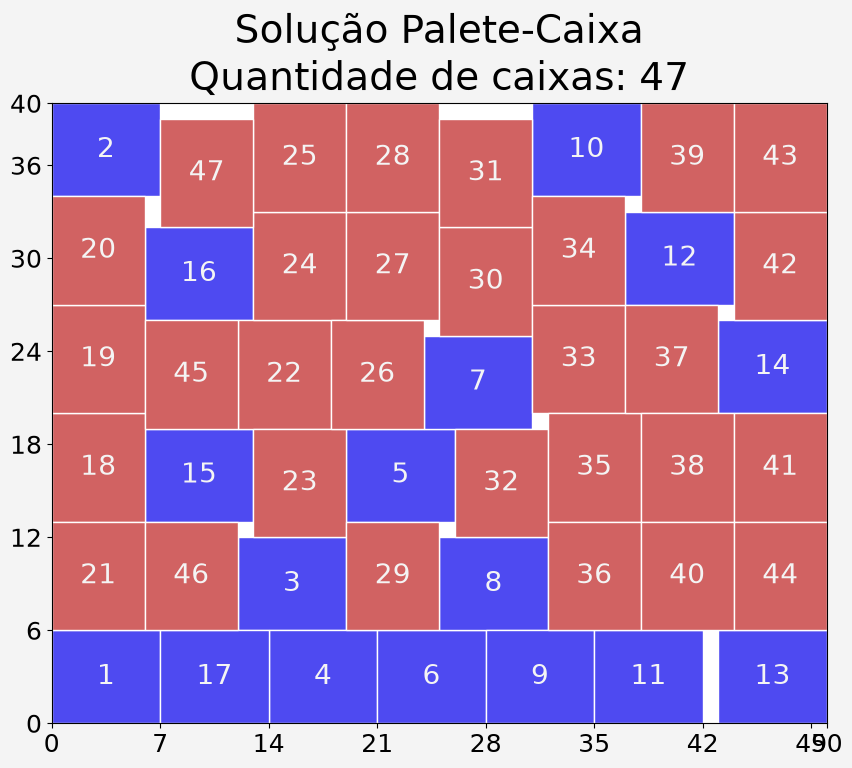

In [154]:
fig, ax = plt.subplots(figsize=(10, 10))
fig.set_facecolor('#f4f4f4')

a = plt.gca()
a.set_xticks(list(range(0, L + 1, l_um)) + [L])
a.set_yticks(list(range(0, W + 1, w_um)) + [W])
a.set_xticklabels(a.get_xticks())
a.set_yticklabels(a.get_yticks())

qtd_caixas = len(variaveis_organizadas)
for indice_caixa, variavel_organizada in enumerate(variaveis_organizadas, 1):
    i, p, q = variavel_organizada
    
    ax.add_patch(plt.Rectangle(xy=(p, q), 
                               width=ls[i - 1], 
                               height=ws[i - 1], 
                               facecolor="#4e4af1" if i == 1 else "#d16262", 
                               edgecolor="white", lw=1,
                               alpha=1,))

    plt.text(x=p + ls[i - 1] / 2, 
             y=q + ws[i - 1] / 2, 
             s=f"{indice_caixa}", 
             fontsize=20,
             color="#f4f4f4",
             ha="center", 
             va="center")

ax.set_title(f"Solução Palete-Caixa\nQuantidade de caixas: {qtd_caixas}",
                fontsize=28)

ax.set_xlim(0, L)
ax.set_ylim(0, W)
ax.set_aspect("equal")

ax.xaxis.set_tick_params(labelsize=18)
ax.yaxis.set_tick_params(labelsize=18)

In [155]:
from copy import deepcopy
solucoes = [deepcopy(variaveis_organizadas)]

In [156]:
from random import random, seed
seed(42)

n = 0
for variavel in prob.variables():
    if variavel.varValue > 0:

        if random() > 0.2:
            continue

        # print(variavel)
        prob += variavel == 0, f"Restricao_3.{n}"
        n += 1
display(prob)

Palete-Caixa:
MAXIMIZE
1*C_(1,_0,_0) + 1*C_(1,_0,_12) + 1*C_(1,_0,_13) + 1*C_(1,_0,_14) + 1*C_(1,_0,_18) + 1*C_(1,_0,_19) + 1*C_(1,_0,_20) + 1*C_(1,_0,_21) + 1*C_(1,_0,_24) + 1*C_(1,_0,_25) + 1*C_(1,_0,_26) + 1*C_(1,_0,_27) + 1*C_(1,_0,_28) + 1*C_(1,_0,_30) + 1*C_(1,_0,_31) + 1*C_(1,_0,_32) + 1*C_(1,_0,_33) + 1*C_(1,_0,_34) + 1*C_(1,_0,_6) + 1*C_(1,_0,_7) + 1*C_(1,_12,_0) + 1*C_(1,_12,_12) + 1*C_(1,_12,_13) + 1*C_(1,_12,_14) + 1*C_(1,_12,_18) + 1*C_(1,_12,_19) + 1*C_(1,_12,_20) + 1*C_(1,_12,_21) + 1*C_(1,_12,_24) + 1*C_(1,_12,_25) + 1*C_(1,_12,_26) + 1*C_(1,_12,_27) + 1*C_(1,_12,_28) + 1*C_(1,_12,_30) + 1*C_(1,_12,_31) + 1*C_(1,_12,_32) + 1*C_(1,_12,_33) + 1*C_(1,_12,_34) + 1*C_(1,_12,_6) + 1*C_(1,_12,_7) + 1*C_(1,_13,_0) + 1*C_(1,_13,_12) + 1*C_(1,_13,_13) + 1*C_(1,_13,_14) + 1*C_(1,_13,_18) + 1*C_(1,_13,_19) + 1*C_(1,_13,_20) + 1*C_(1,_13,_21) + 1*C_(1,_13,_24) + 1*C_(1,_13,_25) + 1*C_(1,_13,_26) + 1*C_(1,_13,_27) + 1*C_(1,_13,_28) + 1*C_(1,_13,_30) + 1*C_(1,_13,_31) + 1*C_(1,_13,_32

In [157]:
print(prob.numVariables())
print(prob.numConstraints())

1150
613


In [158]:
prob.solve(solver)

1

In [159]:
variaveis_organizadas = []
for variavel in prob.variables():
    # print(variavel.name, variavel.varValue)
    if variavel.varValue > 0:
        var_traduzida = dict_traducao[variavel]
        variaveis_organizadas.append(var_traduzida)
display(variaveis_organizadas)

[(1, 0, 14),
 (1, 0, 20),
 (1, 13, 0),
 (1, 13, 34),
 (1, 18, 28),
 (1, 18, 7),
 (1, 20, 34),
 (1, 25, 7),
 (1, 27, 34),
 (1, 31, 28),
 (1, 35, 34),
 (1, 37, 21),
 (1, 43, 14),
 (1, 43, 34),
 (1, 6, 0),
 (1, 6, 34),
 (2, 0, 0),
 (2, 0, 26),
 (2, 0, 33),
 (2, 0, 7),
 (2, 12, 27),
 (2, 12, 6),
 (2, 13, 13),
 (2, 13, 20),
 (2, 19, 14),
 (2, 19, 21),
 (2, 20, 0),
 (2, 25, 13),
 (2, 25, 20),
 (2, 25, 27),
 (2, 26, 0),
 (2, 31, 14),
 (2, 31, 21),
 (2, 32, 0),
 (2, 32, 7),
 (2, 37, 14),
 (2, 38, 0),
 (2, 38, 27),
 (2, 38, 7),
 (2, 44, 0),
 (2, 44, 20),
 (2, 44, 27),
 (2, 44, 7),
 (2, 6, 27),
 (2, 6, 6),
 (2, 7, 13),
 (2, 7, 20)]

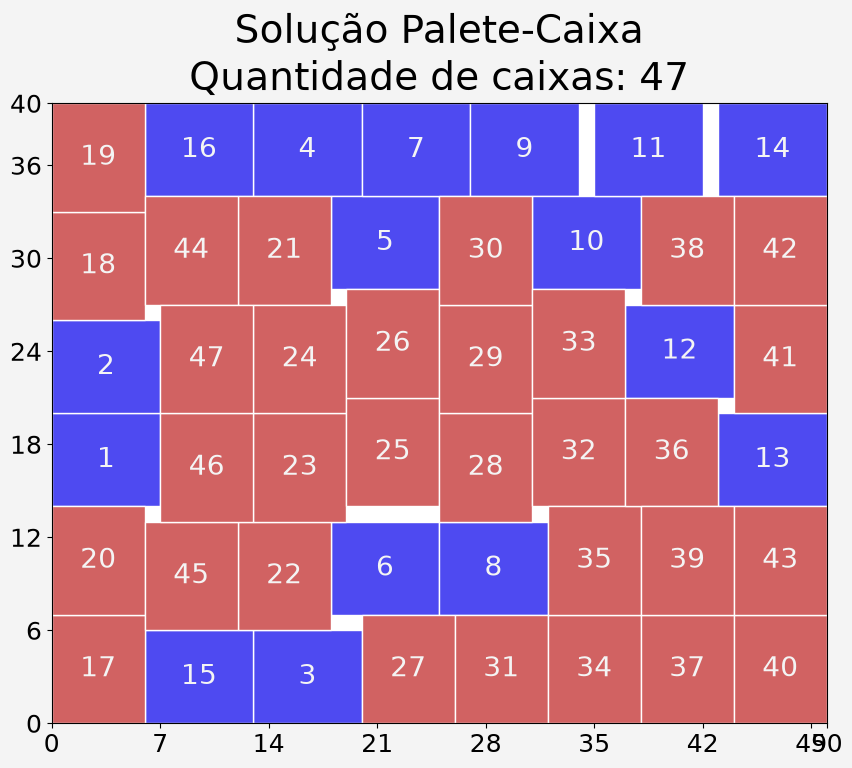

In [160]:
# segunda solução

fig, ax = plt.subplots(figsize=(10, 10))
fig.set_facecolor('#f4f4f4')

a = plt.gca()
a.set_xticks(list(range(0, L + 1, l_um)) + [L])
a.set_yticks(list(range(0, W + 1, w_um)) + [W])
a.set_xticklabels(a.get_xticks())
a.set_yticklabels(a.get_yticks())

qtd_caixas = len(variaveis_organizadas)
for indice_caixa, variavel_organizada in enumerate(variaveis_organizadas, 1):
    i, p, q = variavel_organizada
    
    ax.add_patch(plt.Rectangle(xy=(p, q), 
                               width=ls[i - 1], 
                               height=ws[i - 1], 
                               facecolor="#4e4af1" if i == 1 else "#d16262", 
                               edgecolor="white", lw=1,
                               alpha=1,))

    plt.text(x=p + ls[i - 1] / 2, 
             y=q + ws[i - 1] / 2, 
             s=f"{indice_caixa}", 
             fontsize=20,
             color="#f4f4f4",
             ha="center", 
             va="center")

ax.set_title(f"Solução Palete-Caixa\nQuantidade de caixas: {qtd_caixas}",
                fontsize=28)

ax.set_xlim(0, L)
ax.set_ylim(0, W)
ax.set_aspect("equal")

ax.xaxis.set_tick_params(labelsize=18)
ax.yaxis.set_tick_params(labelsize=18)

In [161]:
solucoes.append(deepcopy(variaveis_organizadas))

In [162]:
# Comando para verificar outros solvers:
print(plp.listSolvers(onlyAvailable=True))
# ['GLPK_CMD', 'PULP_CBC_CMD', 'COIN_CMD', 'HiGHS_CMD']

['PULP_CBC_CMD', 'COIN_CMD']


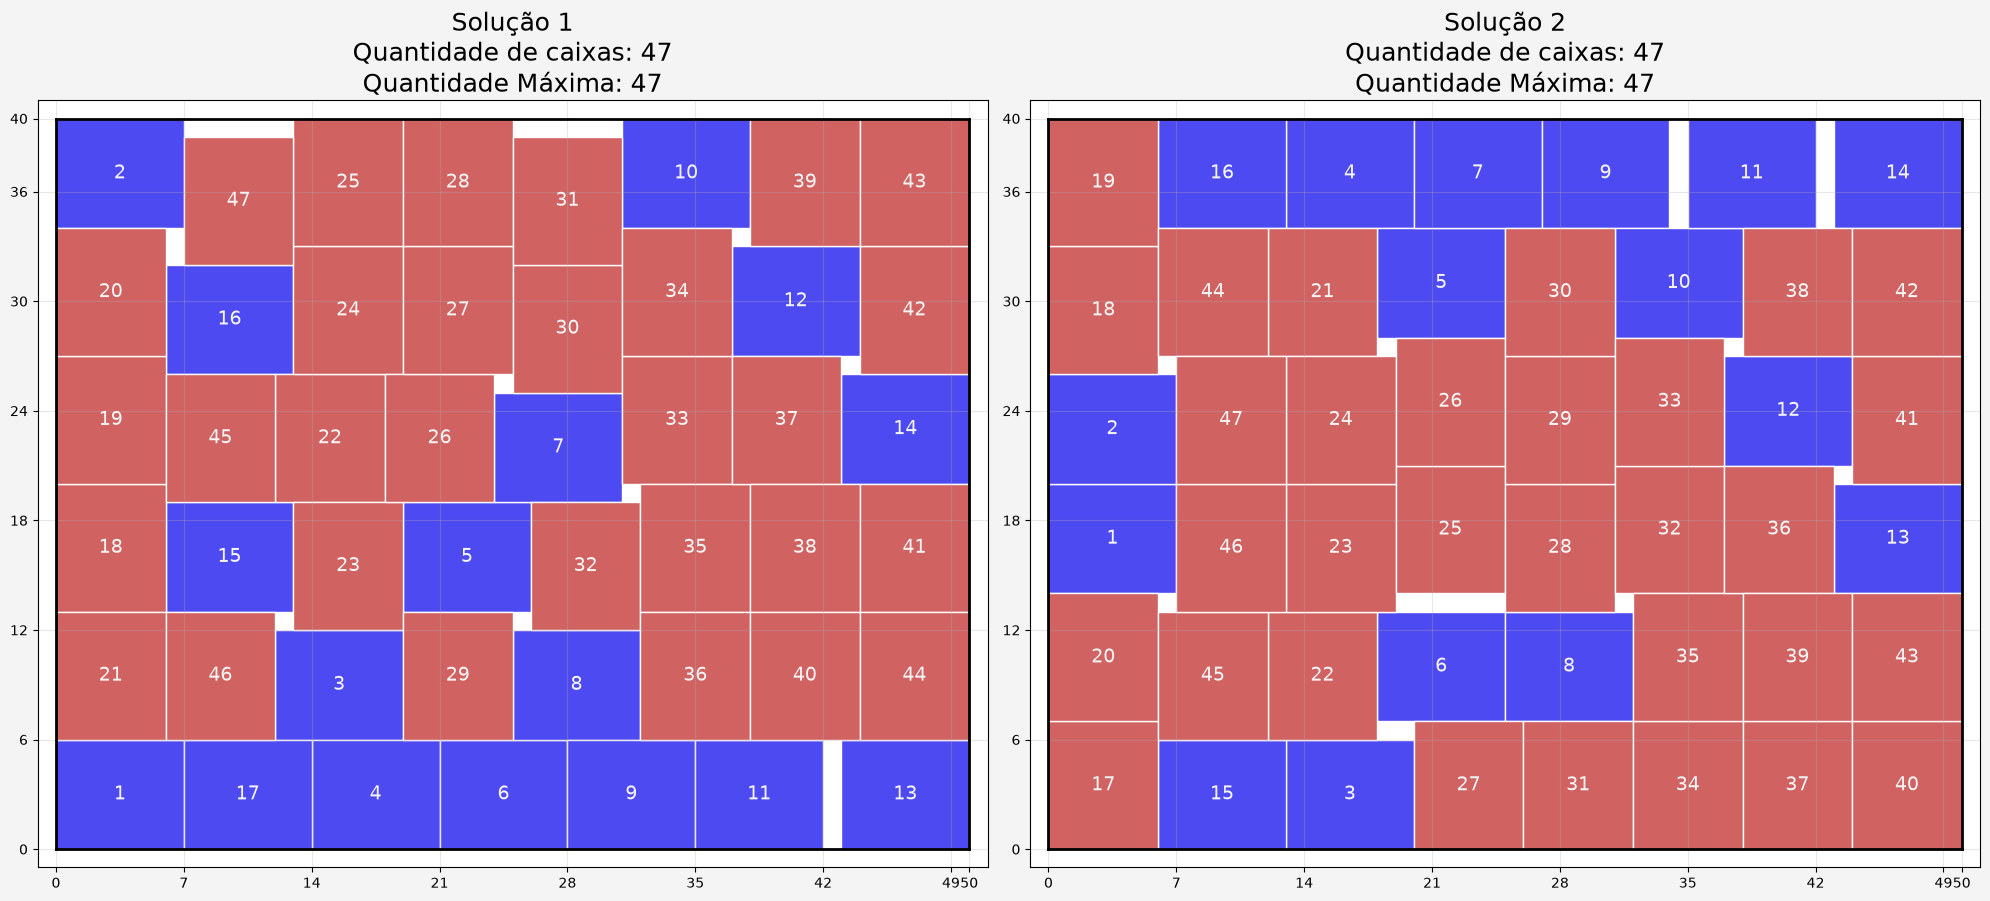

In [163]:
from matplotlib.figure import Figure
from matplotlib.axes import Axes
import numpy as np

fig: Figure
axes: np.ndarray[Axes]

fig, axes = plt.subplots(ncols=2, figsize=(20, 10))
fig.set_facecolor('#f4f4f4')

for idx, (ax, solucao) in enumerate(zip(axes, solucoes[:2]), start=1):
    ax.set_xticks(list(range(0, L + 1, l_um)) + [L])
    ax.set_yticks(list(range(0, W + 1, w_um)) + [W])
    ax.set_xlim(-1, L + 1)
    ax.set_ylim(-1, W + 1)
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)

    # borda da palete
    for x0, y0, x1, y1 in [(0, 0, L, 0), (0, 0, 0, W), (0, W, L, W), (L, 0, L, W)]:
        ax.plot([x0, x1], [y0, y1], 'k-', lw=2)

    for n_caixa, (i, p, q) in enumerate(solucao, start=1):
        ax.add_patch(plt.Rectangle(
            xy=(p, q),
            width=ls[i - 1],
            height=ws[i - 1],
            facecolor="#4e4af1" if i == 1 else "#d16262",
            edgecolor="white",
            lw=1
        ))
        ax.text(
            p + ls[i - 1] / 2,
            q + ws[i - 1] / 2,
            str(n_caixa),
            ha="center",
            va="center",
            fontsize=14,
            color="#f4f4f4"
        )

    ax.set_title(f"Solução {idx}\nQuantidade de caixas: {len(solucao)}\nQuantidade Máxima: {qtd_maxima_caixas}", fontsize=18)

plt.tight_layout()
plt.show()